# Regresión Lineal Múltiple: exploración, selección, validación y predicción

**Cuadernillo didáctico y reutilizable**

---

## Propósito

Este cuadernillo guía, paso a paso, el desarrollo completo de un análisis de **regresión lineal múltiple** en Python. Está diseñado para usarse en clase y para reutilizarse con **cualquier base de datos** que tenga una variable respuesta cuantitativa y varios posibles predictores.

El flujo de trabajo es:

> **Comprender el problema → explorar los datos → preparar los datos → construir el modelo → seleccionar variables → regularizar → validar supuestos → evaluar capacidad predictiva → realizar predicciones → concluir.**

Cada sección responde cinco preguntas:

| # | Pregunta |
|---|---|
| 1 | ¿Qué se está haciendo? |
| 2 | ¿Por qué se hace? |
| 3 | ¿Cómo se ejecuta en Python? |
| 4 | ¿Cómo se interpreta? |
| 5 | ¿Qué debe reportarse en el informe? |

## Objetivos de aprendizaje

Al finalizar, el estudiante deberá ser capaz de:

- identificar una variable respuesta cuantitativa;
- reconocer posibles predictores;
- realizar análisis exploratorio;
- construir modelos de regresión lineal múltiple;
- interpretar coeficientes;
- evaluar multicolinealidad;
- seleccionar variables;
- comprender regularización;
- validar supuestos;
- evaluar ajuste y predicción;
- realizar predicciones;
- formular conclusiones estadísticamente sustentadas.

## Resultados esperados

Al terminar el cuadernillo el estudiante contará con:

1. Un diagnóstico de calidad y un análisis exploratorio documentado de su base.
2. Un modelo OLS completo y varios modelos reducidos (Backward, Forward, Stepwise, criterio AIC).
3. Modelos regularizados (Ridge, Lasso y, opcionalmente, Elastic Net) ajustados con validación cruzada.
4. Una tabla comparativa de alternativas y un **modelo final justificado**, expresado como ecuación.
5. Un diagnóstico de supuestos y observaciones influyentes.
6. Métricas de ajuste (entrenamiento), de predicción (prueba) y de validación cruzada.
7. Predicciones con intervalos de confianza y de predicción.
8. Todos los insumos para redactar el informe final, incluido el anexo de uso de IA.

## Cómo usar este cuadernillo

- Las celdas marcadas con **`✏️ EDITAR`** son las que usted debe adaptar a su propia base.
- Por defecto, el cuadernillo carga una **base de ejemplo** incluida en scikit-learn (*diabetes*, 442 pacientes) para que pueda ejecutarse de principio a fin sin archivos externos.
- Ejecute las celdas **en orden** (menú *Run All* / *Ejecutar todo*). Los resultados numéricos se calculan en cada ejecución: **ningún valor está escrito a mano**.
- Los bloques **📝 Para el informe** indican qué debe llevar a su documento final.
- Los bloques **❓ Preguntas para el estudiante** buscan que usted interprete, no sólo que ejecute.

---
# PARTE 1. Comprensión del problema

## 1.1 ¿Qué es un problema de regresión?

Un problema de **regresión** busca describir, explicar o predecir el valor de una **variable respuesta cuantitativa** $Y$ a partir de un conjunto de **variables predictoras** $X_1, X_2, \dots, X_p$.

El **modelo de regresión lineal múltiple** se escribe:

$$
Y_i = \beta_0+\beta_1X_{1i}+\beta_2X_{2i}+\cdots+\beta_pX_{pi}+\varepsilon_i, \qquad i = 1,\dots,n
$$

| Elemento | Significado |
|---|---|
| $Y_i$ | **Variable respuesta** (dependiente) de la observación $i$. Es lo que se quiere explicar o predecir. |
| $X_{ji}$ | **Variables predictoras** (independientes, explicativas o covariables). |
| $\beta_0$ | **Intercepto**: valor esperado de $Y$ cuando todos los $X_j = 0$ (sólo tiene sentido práctico si ese punto es plausible). |
| $\beta_j$ | **Coeficiente** de $X_j$: cambio esperado en $Y$ por un aumento de una unidad en $X_j$, manteniendo constantes las demás variables. |
| $\varepsilon_i$ | **Error aleatorio**: lo que el modelo no explica. Se supone $E(\varepsilon_i)=0$, varianza constante $\sigma^2$, independencia y (para inferencia) normalidad. |

En forma matricial: $\mathbf{y} = \mathbf{X}\boldsymbol\beta + \boldsymbol\varepsilon$, y el estimador de **Mínimos Cuadrados Ordinarios (OLS)** es

$$
\hat{\boldsymbol\beta} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y},
$$

que minimiza la suma de cuadrados de los residuos $\sum_i (y_i-\hat y_i)^2$.

## 1.2 Explicar vs. predecir

- **Explicar (inferencia):** interesa el signo, magnitud y significancia de cada $\beta_j$, sus intervalos de confianza y el cumplimiento de supuestos.
- **Predecir:** interesa que el modelo acierte en datos **nuevos** (error de prueba, validación cruzada).
- Muchos trabajos buscan **ambos**: por eso este cuadernillo equilibra inferencia estadística y capacidad predictiva.

## ❓ Preguntas para el estudiante

Responda antes de continuar (en esta celda o en su informe):

1. ¿Cuál es el fenómeno que se quiere explicar?
2. ¿Cuál es la variable respuesta?
3. ¿En qué unidades se mide?
4. ¿Qué variables podrían explicarla? ¿Por qué (literatura, conocimiento del problema)?
5. ¿Cuál es la población o unidad de análisis (personas, municipios, viviendas, meses…)?
6. ¿El objetivo es explicar, predecir o ambos?

*Respuestas:*

- ...

> **Ejemplo con la base incluida (diabetes):** la unidad de análisis es el paciente; la variable respuesta `progresion` es una medida cuantitativa de la progresión de la enfermedad un año después de la línea base; los posibles predictores son edad, sexo, índice de masa corporal, presión arterial y seis mediciones séricas. El objetivo es doble: identificar qué variables se asocian con la progresión y predecirla.

## 📝 Para el informe: descripción del problema

Redacte uno o dos párrafos que incluyan:

- contexto del problema y por qué es relevante;
- fuente de los datos (institución, año, forma de recolección);
- unidad de análisis y población a la que se refieren los datos;
- variable respuesta, su definición y unidades;
- predictores considerados y la justificación conceptual de cada uno;
- objetivo del análisis (explicativo, predictivo o ambos).

---
# PARTE 2. Importación de librerías

**¿Qué se hace?** Se cargan las librerías necesarias, organizadas por función.

**¿Por qué?** Tener todas las importaciones al inicio facilita reproducir el análisis y detectar dependencias faltantes.

> Si alguna librería no está instalada, instálela **una sola vez** desde la terminal (`pip install statsmodels seaborn scikit-learn openpyxl`), no dentro del cuadernillo.

In [1]:
# ---------------------------------------------------------------
# Manipulación de datos
# ---------------------------------------------------------------
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------------
# Gráficos
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# Estadística e inferencia (modelos OLS, pruebas de supuestos)
# ---------------------------------------------------------------
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from scipy import stats

# ---------------------------------------------------------------
# Aprendizaje automático (partición, validación, regularización)
# ---------------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.linear_model import Lasso, LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ---------------------------------------------------------------
# Métricas
# ---------------------------------------------------------------
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# ---------------------------------------------------------------
# Presentación
# ---------------------------------------------------------------
from IPython.display import display, Markdown, Math
import warnings

# Estilo de gráficos y formato de tablas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Se silencian sólo avisos de convergencia/deprecación que no afectan los resultados
warnings.filterwarnings("ignore", category=FutureWarning)

import sklearn, statsmodels
print("Versiones -> pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__,
      "| statsmodels:", statsmodels.__version__)

Versiones -> pandas: 3.0.2 | scikit-learn: 1.8.0 | statsmodels: 0.15.0


### Parámetros generales del análisis ✏️ EDITAR

Todos los parámetros que controlan la reproducibilidad y los umbrales del análisis se definen **una sola vez** aquí.

In [2]:
# ===============================================================
# ✏️ EDITAR: parámetros generales
# ===============================================================
RANDOM_STATE = 123     # semilla para que los resultados sean reproducibles
TEST_SIZE    = 0.20    # proporción de datos reservada para prueba
ALPHA        = 0.05    # nivel de significancia para pruebas y selección
N_FOLDS      = 5       # número de particiones en validación cruzada

# Objeto de validación cruzada reutilizado en todo el cuadernillo
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

---
# PARTE 3. Carga y reconocimiento inicial de los datos

**¿Qué se hace?** Se carga la base (CSV o Excel) y se realiza una primera revisión.

**¿Por qué?** Antes de modelar hay que saber cuántas observaciones y variables hay, de qué tipo son y si existen problemas evidentes (faltantes, duplicados, identificadores).

**¿Cómo cargar su propia base?**

```python
df = pd.read_csv("archivo.csv")            # CSV separado por comas
df = pd.read_csv("archivo.csv", sep=";")   # CSV exportado desde Excel en español
df = pd.read_excel("archivo.xlsx")         # Excel (requiere openpyxl)
```

En la celda siguiente basta con escribir la ruta en `RUTA_DATOS`. Si se deja en `None`, se usa la base de ejemplo.

In [3]:
# ===============================================================
# ✏️ EDITAR: origen de los datos
# ===============================================================
RUTA_DATOS    = None   # Ej.: "mi_base.csv", "datos/mi_base.xlsx". None = base de ejemplo
SEPARADOR_CSV = ","    # Use ";" si su CSV fue exportado desde Excel en español
DECIMAL_CSV   = "."    # Use "," si los decimales vienen con coma
HOJA_EXCEL    = 0      # Nombre o índice de la hoja de Excel


def cargar_base_ejemplo():
    """Base 'diabetes' de scikit-learn en unidades originales (no escaladas).

    442 pacientes. Variable respuesta: medida cuantitativa de progresión de la
    enfermedad un año después de la línea base. Se renombran las columnas para
    facilitar la lectura y 'sexo' se deja como variable categórica (códigos 1 y 2
    de la fuente original) para ilustrar la codificación dummy.
    """
    from sklearn.datasets import load_diabetes
    datos = load_diabetes(as_frame=True, scaled=False).frame
    nombres = {
        "age": "edad", "sex": "sexo", "bmi": "imc", "bp": "presion_arterial",
        "s1": "colesterol_total", "s2": "ldl", "s3": "hdl",
        "s4": "ratio_col_hdl", "s5": "log_trigliceridos", "s6": "glucosa",
        "target": "progresion",
    }
    datos = datos.rename(columns=nombres)
    datos["sexo"] = datos["sexo"].map({1.0: "Grupo_1", 2.0: "Grupo_2"})
    return datos


def cargar_datos(ruta=None, sep=",", decimal=".", hoja=0):
    """Carga un CSV o un Excel según la extensión. Si ruta es None, carga el ejemplo."""
    if ruta is None:
        print("Se cargó la base de EJEMPLO (diabetes, scikit-learn).")
        return cargar_base_ejemplo()
    ruta = Path(ruta)
    extension = ruta.suffix.lower()
    if extension in [".csv", ".txt"]:
        datos = pd.read_csv(ruta, sep=sep, decimal=decimal)
    elif extension in [".xlsx", ".xls", ".xlsm"]:
        datos = pd.read_excel(ruta, sheet_name=hoja)
    else:
        raise ValueError(f"Extensión no reconocida: {extension}. Use CSV o Excel.")
    print(f"Se cargó la base: {ruta.name}")
    return datos


df = cargar_datos(RUTA_DATOS, sep=SEPARADOR_CSV, decimal=DECIMAL_CSV, hoja=HOJA_EXCEL)

Se cargó la base de EJEMPLO (diabetes, scikit-learn).


### Diccionario de variables de la base de ejemplo

| Variable | Descripción |
|---|---|
| `edad` | Edad (años) |
| `sexo` | Sexo, codificado en la fuente como 1 y 2 (aquí `Grupo_1`, `Grupo_2`) |
| `imc` | Índice de masa corporal (kg/m²) |
| `presion_arterial` | Presión arterial media |
| `colesterol_total` | Colesterol sérico total |
| `ldl` | Lipoproteínas de baja densidad |
| `hdl` | Lipoproteínas de alta densidad |
| `ratio_col_hdl` | Colesterol total / HDL |
| `log_trigliceridos` | Logaritmo del nivel sérico de triglicéridos |
| `glucosa` | Nivel de glucosa en sangre |
| `progresion` | **Variable respuesta**: medida cuantitativa de progresión de la enfermedad a un año |

> ✏️ Si usa su propia base, reemplace esta tabla por el diccionario de sus variables.

## 3.1 Dimensiones

`df.shape` devuelve *(número de filas, número de columnas)*. Las filas son las observaciones (unidades de análisis) y las columnas las variables.

In [4]:
print(f"Observaciones (filas): {df.shape[0]}")
print(f"Variables (columnas):  {df.shape[1]}")
df.shape

Observaciones (filas): 442
Variables (columnas):  11


(442, 11)

## 3.2 Primeras filas y nombres de columnas

Permiten verificar que la base se leyó correctamente (separador, encabezados, decimales).

In [5]:
display(df.head())
print("Columnas:", list(df.columns))

,edad,sexo,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,progresion
0,59.0000,Grupo_2,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000,151.0000
1,48.0000,Grupo_1,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000,75.0000
2,72.0000,Grupo_2,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000,141.0000
3,24.0000,Grupo_1,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000,206.0000
4,50.0000,Grupo_1,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000,135.0000


Columnas: ['edad', 'sexo', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'progresion']


## 3.3 Tipos de variables

`df.info()` muestra el tipo de dato de cada columna y cuántos valores **no nulos** tiene.

- `float64` / `int64`: numéricas.
- `object` / `str` / `category`: texto o categorías.
- Si una variable que debería ser numérica aparece como texto, suele deberse a separadores decimales, símbolos (`$`, `%`) o celdas con texto como "ND".

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   edad               442 non-null    float64
 1   sexo               442 non-null    str    
 2   imc                442 non-null    float64
 3   presion_arterial   442 non-null    float64
 4   colesterol_total   442 non-null    float64
 5   ldl                442 non-null    float64
 6   hdl                442 non-null    float64
 7   ratio_col_hdl      442 non-null    float64
 8   log_trigliceridos  442 non-null    float64
 9   glucosa            442 non-null    float64
 10  progresion         442 non-null    float64
dtypes: float64(10), str(1)
memory usage: 38.1 KB


## 3.4 Estadísticos descriptivos

`df.describe(include="all")` resume todas las columnas:

- Para numéricas: `count`, `mean` (media), `std` (desviación estándar), `min`, cuartiles (`25%`, `50%` = mediana, `75%`) y `max`.
- Para categóricas: `count`, `unique` (número de categorías), `top` (categoría más frecuente) y `freq` (su frecuencia).

Revise si los mínimos y máximos son **plausibles** (edades negativas, porcentajes mayores a 100, etc.).

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,442.0000,NaN,NaN,NaN,48.5181,13.1090,19.0000,38.2500,50.0000,59.0000,79.0000
sexo,442,2,Grupo_1,235,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imc,442.0000,NaN,NaN,NaN,26.3758,4.4181,18.0000,23.2000,25.7000,29.2750,42.2000
presion_arterial,442.0000,NaN,NaN,NaN,94.6470,13.8313,62.0000,84.0000,93.0000,105.0000,133.0000
colesterol_total,442.0000,NaN,NaN,NaN,189.1403,34.6081,97.0000,164.2500,186.0000,209.7500,301.0000
ldl,442.0000,NaN,NaN,NaN,115.4391,30.4131,41.6000,96.0500,113.0000,134.5000,242.4000
hdl,442.0000,NaN,NaN,NaN,49.7885,12.9342,22.0000,40.2500,48.0000,57.7500,99.0000
ratio_col_hdl,442.0000,NaN,NaN,NaN,4.0702,1.2904,2.0000,3.0000,4.0000,5.0000,9.0900
log_trigliceridos,442.0000,NaN,NaN,NaN,4.6414,0.5224,3.2581,4.2767,4.6200,4.9972,6.1070
glucosa,442.0000,NaN,NaN,NaN,91.2602,11.4963,58.0000,83.2500,91.0000,98.0000,124.0000


## 3.5 Valores faltantes y duplicados

- `df.isna().sum()`: número de celdas vacías por columna.
- `df.duplicated().sum()`: número de filas **idénticas** a otra fila anterior.

Un duplicado puede ser un error de digitación o una observación legítimamente repetida: **se reporta, no se elimina automáticamente**.

In [8]:
faltantes = df.isna().sum()
print("Faltantes por columna:")
display(faltantes.to_frame("n_faltantes").assign(pct=lambda t: 100 * t["n_faltantes"] / len(df)))
print(f"Filas duplicadas: {df.duplicated().sum()}")

Faltantes por columna:


,n_faltantes,pct
edad,0,0.0000
sexo,0,0.0000
imc,0,0.0000
presion_arterial,0,0.0000
colesterol_total,0,0.0000
ldl,0,0.0000
hdl,0,0.0000
ratio_col_hdl,0,0.0000
log_trigliceridos,0,0.0000
glucosa,0,0.0000


Filas duplicadas: 0


## 3.6 Cardinalidad y posibles identificadores

La **cardinalidad** es el número de valores distintos de cada variable.

- Una variable con **un solo valor** es constante: no aporta información.
- Una variable con **tantos valores como filas** (y que no es una medición continua) suele ser un **identificador** (código, número de documento, consecutivo). Los identificadores **no deben usarse como predictores**.

In [9]:
cardinalidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(dropna=True),
    "pct_unicos": 100 * df.nunique(dropna=True) / len(df),
})
display(cardinalidad)

# Heurística: columnas con valores únicos en todas las filas o cuyo nombre sugiere un código
posibles_id = [
    c for c in df.columns
    if (df[c].nunique(dropna=True) == len(df) and not pd.api.types.is_float_dtype(df[c]))
    or c.lower() in ("id", "codigo", "código", "consecutivo")
    or c.lower().startswith("id_")
]
print("Posibles identificadores (revisar manualmente):", posibles_id if posibles_id else "ninguno")

,tipo,n_unicos,pct_unicos
edad,float64,58,13.1222
sexo,str,2,0.4525
imc,float64,163,36.8778
presion_arterial,float64,100,22.6244
colesterol_total,float64,141,31.9005
ldl,float64,302,68.3258
hdl,float64,63,14.2534
ratio_col_hdl,float64,66,14.9321
log_trigliceridos,float64,184,41.6290
glucosa,float64,56,12.6697


Posibles identificadores (revisar manualmente): ninguno


## 3.7 Definición de la variable respuesta ✏️ EDITAR

Se declara desde ahora cuál es la variable respuesta, porque el análisis exploratorio la trata de manera especial.

In [10]:
# ===============================================================
# ✏️ EDITAR: nombre exacto de la variable respuesta (Y)
# ===============================================================
variable_objetivo = "progresion"

# ✏️ EDITAR: columnas que NO deben usarse como predictores (identificadores, fechas, etc.)
columnas_excluir = list(posibles_id)

assert variable_objetivo in df.columns, "La variable objetivo no existe en la base."
assert pd.api.types.is_numeric_dtype(df[variable_objetivo]), "La variable objetivo debe ser numérica."
print("Variable respuesta:", variable_objetivo)
print("Columnas excluidas del modelamiento:", columnas_excluir if columnas_excluir else "ninguna")

Variable respuesta: progresion
Columnas excluidas del modelamiento: ninguna


---
# PARTE 4. Cuadernillo de Análisis Exploratorio de Datos (EDA)

**¿Qué se hace?** Se describe cada variable, su calidad y sus relaciones con la respuesta y entre sí.

**¿Por qué?** El EDA permite detectar errores, decidir transformaciones, anticipar multicolinealidad y proponer predictores razonables **antes** de ajustar modelos. Un modelo sobre datos no explorados puede ser numéricamente correcto y conceptualmente erróneo.

> Todas las funciones de esta parte son genéricas: funcionan con cualquier base una vez definida `variable_objetivo`.

## 4.1 Identificación de tipos de variables

Se clasifica automáticamente cada variable y **luego se revisa manualmente**:

- **Cuantitativa**: numérica con muchos valores distintos (continua o discreta amplia).
- **Cuantitativa discreta / posible ordinal**: numérica con pocos valores (p. ej., escala 1–5). Debe decidirse si se trata como numérica u ordinal.
- **Binaria**: exactamente dos valores (0/1, Sí/No).
- **Cualitativa (nominal)**: categorías sin orden.

In [11]:
def clasificar_variables(datos, max_niveles_discreta=10):
    """Propone un tipo para cada variable. La decisión final es del analista."""
    filas = []
    for col in datos.columns:
        s = datos[col]
        n_unicos = s.nunique(dropna=True)
        es_numerica = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        if n_unicos == 2:
            tipo = "binaria"
        elif es_numerica and n_unicos <= max_niveles_discreta:
            tipo = "cuantitativa discreta / posible ordinal"
        elif es_numerica:
            tipo = "cuantitativa"
        else:
            tipo = "cualitativa"
        filas.append({"variable": col, "dtype": str(s.dtype), "n_unicos": n_unicos,
                      "numerica_en_python": es_numerica, "tipo_propuesto": tipo})
    return pd.DataFrame(filas).set_index("variable")


tabla_tipos = clasificar_variables(df.drop(columns=columnas_excluir))
display(tabla_tipos)

,dtype,n_unicos,numerica_en_python,tipo_propuesto
variable,,,,
edad,float64,58,True,cuantitativa
sexo,str,2,False,binaria
imc,float64,163,True,cuantitativa
presion_arterial,float64,100,True,cuantitativa
colesterol_total,float64,141,True,cuantitativa
ldl,float64,302,True,cuantitativa
hdl,float64,63,True,cuantitativa
ratio_col_hdl,float64,66,True,cuantitativa
log_trigliceridos,float64,184,True,cuantitativa


### Revisión manual ✏️ EDITAR

Las listas siguientes se llenan automáticamente, pero **usted debe revisarlas**. Por ejemplo, un código de municipio numérico es cualitativo, y una escala Likert puede tratarse como ordinal.

- `vars_numericas`: variables numéricas (incluye binarias 0/1 numéricas).
- `vars_categoricas`: variables de texto o categorías (se convertirán en dummies).
- `vars_ordinales`: opcional, sólo para documentar variables con orden natural.

In [12]:
# Detección automática (la variable objetivo y las excluidas no se incluyen)
candidatas = [c for c in df.columns if c != variable_objetivo and c not in columnas_excluir]
vars_numericas = [c for c in candidatas if tabla_tipos.loc[c, "numerica_en_python"]]
vars_categoricas = [c for c in candidatas if not tabla_tipos.loc[c, "numerica_en_python"]]
vars_ordinales = []   # ✏️ EDITAR si aplica, p. ej. ["nivel_educativo"]

# ✏️ EDITAR: mueva variables entre listas si la detección no es correcta, por ejemplo:
# vars_numericas.remove("codigo_municipio"); vars_categoricas.append("codigo_municipio")

# Las categóricas se tratan como texto para que la codificación sea consistente
for c in vars_categoricas:
    df[c] = df[c].astype("string")

print("Numéricas  :", vars_numericas)
print("Categóricas:", vars_categoricas)
print("Ordinales  :", vars_ordinales if vars_ordinales else "ninguna declarada")

Numéricas  : ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa']
Categóricas: ['sexo']
Ordinales  : ninguna declarada


## 4.2 Calidad de los datos

Se revisan: faltantes, duplicados, valores imposibles, categorías inconsistentes, variables constantes y variables con demasiados valores únicos.

> **Principio:** aquí **no se elimina nada automáticamente**. Se documentan los problemas y se decide, con justificación, qué hacer con cada uno.

In [13]:
def diagnostico_calidad(datos, umbral_cardinalidad=0.5, max_categorias=20):
    """Tabla de calidad por variable."""
    n = len(datos)
    filas = []
    for col in datos.columns:
        s = datos[col]
        n_unicos = s.nunique(dropna=True)
        es_num = pd.api.types.is_numeric_dtype(s)
        alertas = []
        if s.isna().any():
            alertas.append("faltantes")
        if n_unicos <= 1:
            alertas.append("constante")
        if not es_num and (n_unicos > max_categorias or n_unicos / n > umbral_cardinalidad):
            alertas.append("alta cardinalidad")
        filas.append({"variable": col, "n_faltantes": int(s.isna().sum()),
                      "pct_faltantes": 100 * s.isna().mean(), "n_unicos": n_unicos,
                      "alertas": ", ".join(alertas) if alertas else "-"})
    return pd.DataFrame(filas).set_index("variable")


display(diagnostico_calidad(df))
print(f"Filas duplicadas completas: {df.duplicated().sum()}")

,n_faltantes,pct_faltantes,n_unicos,alertas
variable,,,,
edad,0,0.0000,58,-
sexo,0,0.0000,2,-
imc,0,0.0000,163,-
presion_arterial,0,0.0000,100,-
colesterol_total,0,0.0000,141,-
ldl,0,0.0000,302,-
hdl,0,0.0000,63,-
ratio_col_hdl,0,0.0000,66,-
log_trigliceridos,0,0.0000,184,-


Filas duplicadas completas: 0


### Valores imposibles ✏️ EDITAR

Defina el rango plausible de cada variable según el conocimiento del problema. El código **cuenta** los valores fuera de rango; no los elimina.

In [14]:
# ===============================================================
# ✏️ EDITAR: rangos plausibles {variable: (mínimo, máximo)}
# Las variables que no existan en la base se ignoran.
# ===============================================================
rangos_validos = {
    "edad": (0, 120),
    "imc": (10, 80),
    "presion_arterial": (30, 250),
    "progresion": (0, None),
}

def revisar_rangos(datos, rangos):
    filas = []
    for var, (minimo, maximo) in rangos.items():
        if var not in datos.columns:
            continue
        s = datos[var]
        bajo = (s < minimo).sum() if minimo is not None else 0
        alto = (s > maximo).sum() if maximo is not None else 0
        filas.append({"variable": var, "minimo_permitido": minimo, "maximo_permitido": maximo,
                      "min_observado": s.min(), "max_observado": s.max(),
                      "n_fuera_de_rango": int(bajo + alto)})
    return pd.DataFrame(filas)

display(revisar_rangos(df, rangos_validos))

,variable,minimo_permitido,maximo_permitido,min_observado,max_observado,n_fuera_de_rango
0,edad,0,120.0000,19.0000,79.0000,0
1,imc,10,80.0000,18.0000,42.2000,0
2,presion_arterial,30,250.0000,62.0000,133.0000,0
3,progresion,0,NaN,25.0000,346.0000,0


### Categorías inconsistentes

Una misma categoría escrita de formas distintas (`"Bogota"`, `"bogotá "`, `"BOGOTÁ"`) se cuenta como categorías diferentes. Se compara el número de categorías antes y después de normalizar mayúsculas y espacios.

In [15]:
def revisar_categorias(datos, columnas):
    filas = []
    for col in columnas:
        original = datos[col].dropna()
        normalizada = original.str.strip().str.lower()
        filas.append({"variable": col, "categorias_originales": original.nunique(),
                      "categorias_normalizadas": normalizada.nunique(),
                      "posible_inconsistencia": original.nunique() != normalizada.nunique()})
    return pd.DataFrame(filas)

if vars_categoricas:
    display(revisar_categorias(df, vars_categoricas))
    for col in vars_categoricas:
        print(f"\nCategorías de '{col}':")
        display(df[col].value_counts(dropna=False).to_frame("frecuencia"))
else:
    print("No hay variables categóricas.")

,variable,categorias_originales,categorias_normalizadas,posible_inconsistencia
0,sexo,2,2,False



Categorías de 'sexo':


,frecuencia
sexo,
Grupo_1,235
Grupo_2,207


**Interpretación:** registre cada alerta y la decisión tomada (corregir, recodificar, excluir la variable, imputar, mantener). Si no hay alertas, repórtelo explícitamente: *"no se encontraron faltantes, duplicados ni valores fuera de rango"*.

## 4.3 Análisis univariado

### Variables cuantitativas

| Estadístico | Qué indica |
|---|---|
| Media | Centro de gravedad; sensible a valores extremos. |
| Mediana | Valor central; robusta a extremos. Si difiere mucho de la media, hay asimetría. |
| Desviación estándar | Dispersión típica alrededor de la media. |
| Cuartiles (Q1, Q3) y RIC | Dispersión del 50% central. |
| Rango | Máximo − mínimo. |
| Asimetría | ≈0 simétrica; >0 cola a la derecha; <0 cola a la izquierda. |
| Curtosis (exceso) | >0 colas más pesadas que la normal. |

In [16]:
def descriptivos_numericos(datos, columnas):
    d = datos[columnas]
    tabla = pd.DataFrame({
        "n": d.count(), "media": d.mean(), "mediana": d.median(), "desv_est": d.std(),
        "min": d.min(), "Q1": d.quantile(0.25), "Q3": d.quantile(0.75), "max": d.max(),
    })
    tabla["rango"] = tabla["max"] - tabla["min"]
    tabla["RIC"] = tabla["Q3"] - tabla["Q1"]
    tabla["asimetria"] = d.skew()
    tabla["curtosis"] = d.kurt()
    return tabla

cols_num_eda = vars_numericas + [variable_objetivo]
tabla_descriptivos = descriptivos_numericos(df, cols_num_eda)
display(tabla_descriptivos)

,n,media,mediana,desv_est,min,Q1,Q3,max,rango,RIC,asimetria,curtosis
edad,442,48.5181,50.0000,13.1090,19.0000,38.2500,59.0000,79.0000,60.0000,20.7500,-0.2314,-0.6712
imc,442,26.3758,25.7000,4.4181,18.0000,23.2000,29.2750,42.2000,24.2000,6.0750,0.5981,0.0951
presion_arterial,442,94.6470,93.0000,13.8313,62.0000,84.0000,105.0000,133.0000,71.0000,21.0000,0.2907,-0.5328
colesterol_total,442,189.1403,186.0000,34.6081,97.0000,164.2500,209.7500,301.0000,204.0000,45.5000,0.3781,0.2329
ldl,442,115.4391,113.0000,30.4131,41.6000,96.0500,134.5000,242.4000,200.8000,38.4500,0.4366,0.6014
hdl,442,49.7885,48.0000,12.9342,22.0000,40.2500,57.7500,99.0000,77.0000,17.5000,0.7993,0.9815
ratio_col_hdl,442,4.0702,4.0000,1.2904,2.0000,3.0000,5.0000,9.0900,7.0900,2.0000,0.7354,0.4444
log_trigliceridos,442,4.6414,4.6200,0.5224,3.2581,4.2767,4.9972,6.1070,2.8489,0.7205,0.2918,-0.1344
glucosa,442,91.2602,91.0000,11.4963,58.0000,83.2500,98.0000,124.0000,66.0000,14.7500,0.2079,0.2369
progresion,442,152.1335,140.5000,77.0930,25.0000,87.0000,211.5000,346.0000,321.0000,124.5000,0.4406,-0.8831


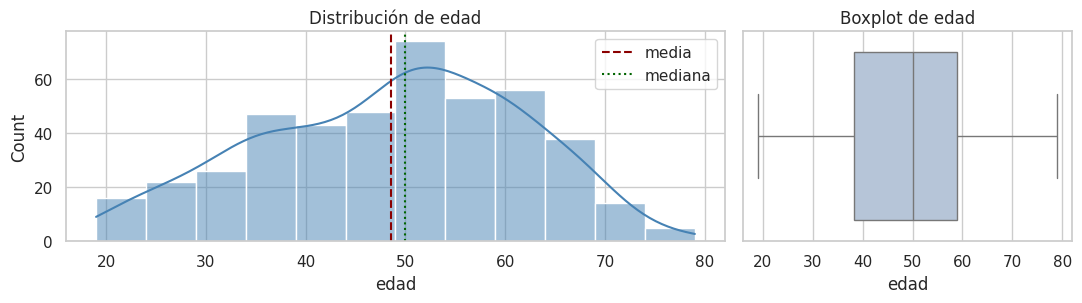

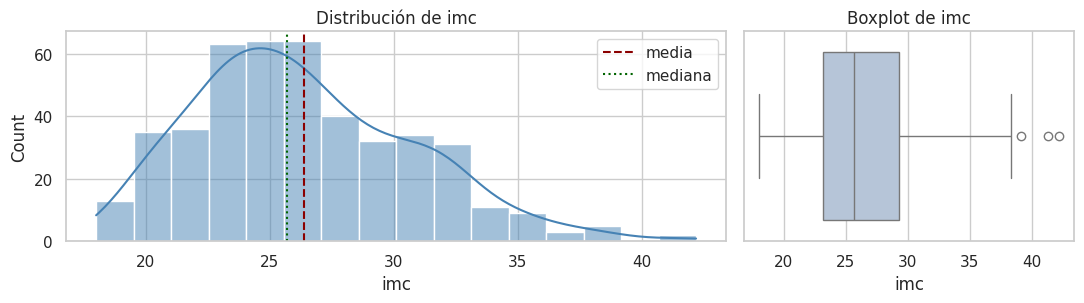

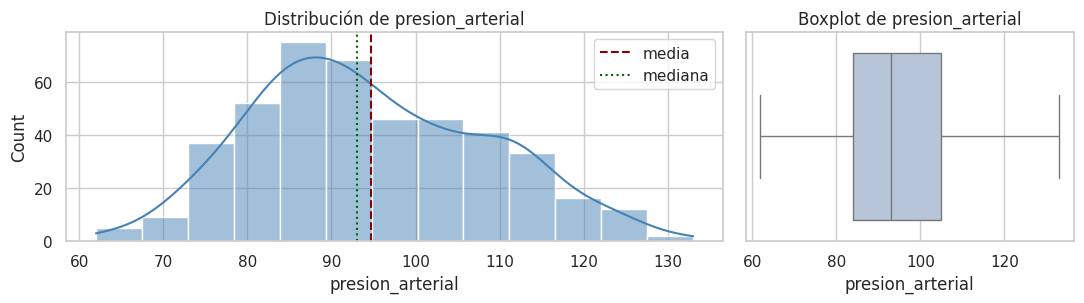

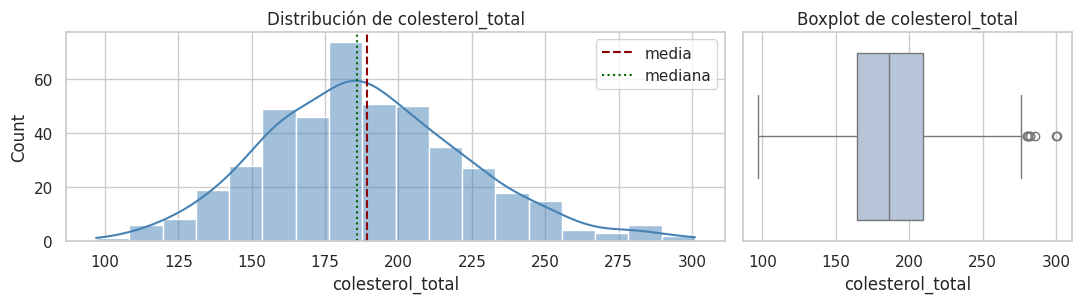

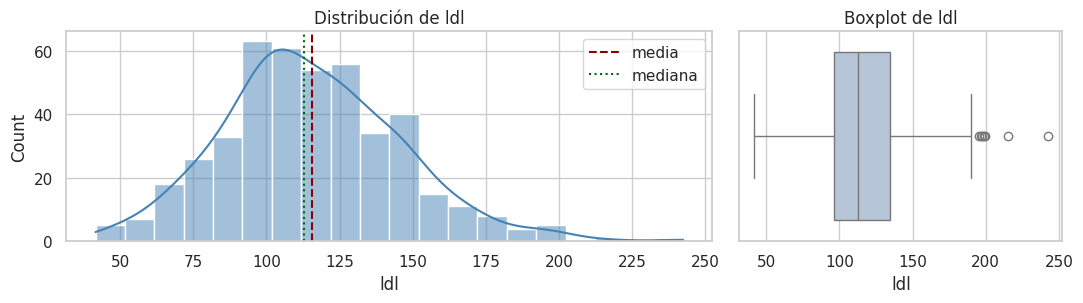

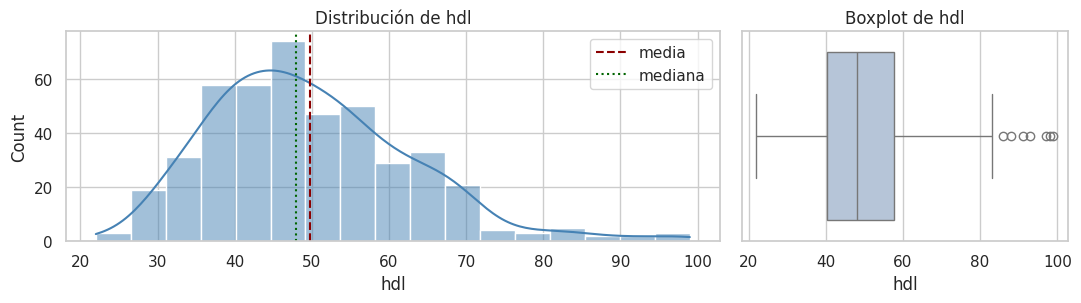

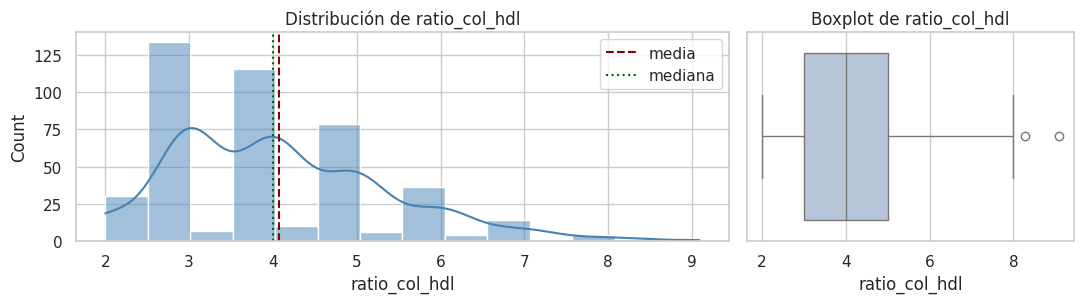

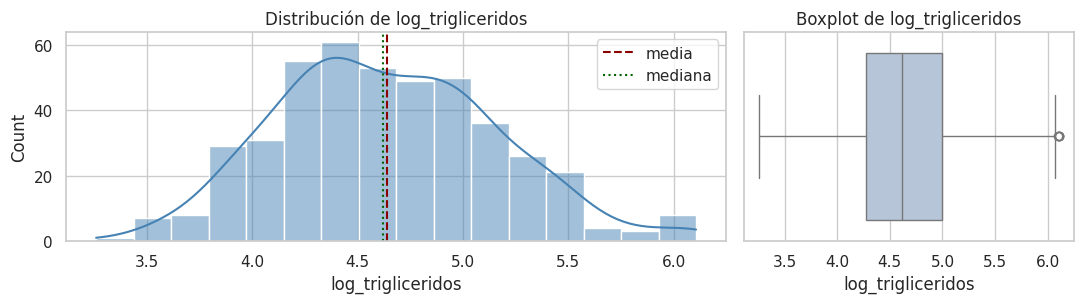

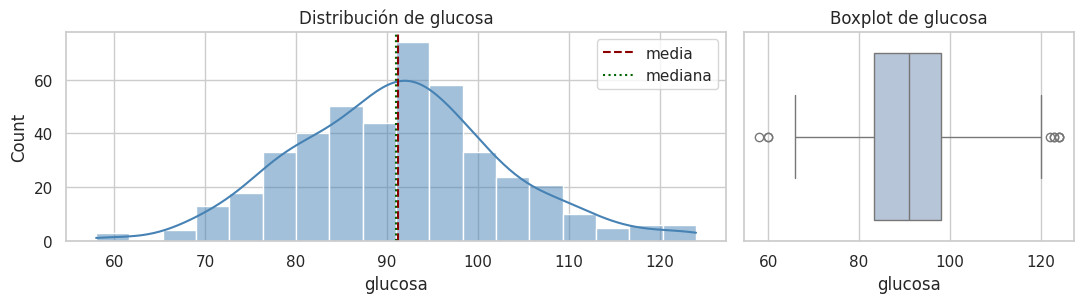

In [17]:
def graficar_univariado_numerico(datos, columnas):
    """Histograma con curva de densidad (KDE) y boxplot para cada variable."""
    for col in columnas:
        fig, ejes = plt.subplots(1, 2, figsize=(11, 3.2),
                                 gridspec_kw={"width_ratios": [2, 1]})
        sns.histplot(datos[col].dropna(), kde=True, ax=ejes[0], color="steelblue")
        ejes[0].axvline(datos[col].mean(), color="darkred", ls="--", label="media")
        ejes[0].axvline(datos[col].median(), color="darkgreen", ls=":", label="mediana")
        ejes[0].legend()
        ejes[0].set_title(f"Distribución de {col}")
        sns.boxplot(x=datos[col], ax=ejes[1], color="lightsteelblue")
        ejes[1].set_title(f"Boxplot de {col}")
        plt.tight_layout()
        plt.show()

graficar_univariado_numerico(df, vars_numericas)

### Variables categóricas

Se reportan frecuencias absolutas, porcentajes y un gráfico de barras. Categorías con muy pocas observaciones pueden generar coeficientes inestables y conviene evaluar agruparlas.

**sexo**

,frecuencia,porcentaje
sexo,,
Grupo_1,235,53.1674
Grupo_2,207,46.8326


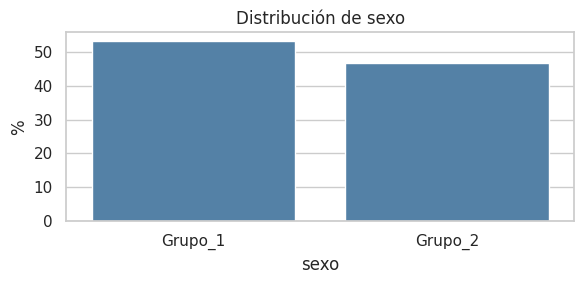

In [18]:
def univariado_categorico(datos, columnas):
    for col in columnas:
        tabla = (datos[col].value_counts(dropna=False).to_frame("frecuencia")
                 .assign(porcentaje=lambda t: 100 * t["frecuencia"] / t["frecuencia"].sum()))
        display(Markdown(f"**{col}**"))
        display(tabla)
        fig, ax = plt.subplots(figsize=(6, 3))
        sns.barplot(x=tabla.index.astype(str).tolist(), y=tabla["porcentaje"].to_numpy(),
                    ax=ax, color="steelblue")
        ax.set_ylabel("%"); ax.set_xlabel(col); ax.set_title(f"Distribución de {col}")
        plt.tight_layout(); plt.show()

if vars_categoricas:
    univariado_categorico(df, vars_categoricas)
else:
    print("No hay variables categóricas.")

## 4.4 Variable respuesta

La variable respuesta merece un análisis propio: su **distribución**, **asimetría**, **valores atípicos**, **concentración** (muchos valores repetidos o ceros) y **unidades**.

> La regresión lineal **no exige** que $Y$ sea normal; el supuesto de normalidad es sobre los **residuos**. Sin embargo, una $Y$ muy asimétrica suele producir residuos asimétricos y heterocedásticos, y puede sugerir una transformación (por ejemplo, logaritmo).

,progresion
n,442.0000
media,152.1335
mediana,140.5000
desv_est,77.0930
coef_variacion_%,50.6746
min,25.0000
max,346.0000
asimetria,0.4406
curtosis,-0.8831
atipicos_regla_1.5RIC,0.0000


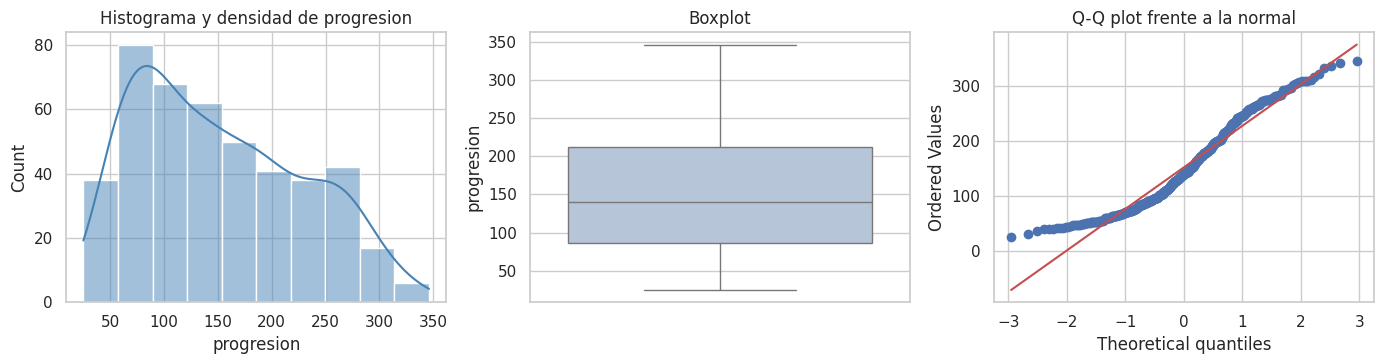

In [19]:
y_completa = df[variable_objetivo].dropna()

q1, q3 = y_completa.quantile([0.25, 0.75])
ric = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * ric, q3 + 1.5 * ric
n_atipicos_y = int(((y_completa < lim_inf) | (y_completa > lim_sup)).sum())

resumen_y = pd.Series({
    "n": len(y_completa), "media": y_completa.mean(), "mediana": y_completa.median(),
    "desv_est": y_completa.std(), "coef_variacion_%": 100 * y_completa.std() / y_completa.mean(),
    "min": y_completa.min(), "max": y_completa.max(), "asimetria": y_completa.skew(),
    "curtosis": y_completa.kurt(), "atipicos_regla_1.5RIC": n_atipicos_y,
    "valor_mas_frecuente": y_completa.mode().iloc[0],
    "%_valor_mas_frecuente": 100 * (y_completa == y_completa.mode().iloc[0]).mean(),
    "%_ceros": 100 * (y_completa == 0).mean(),
})
display(resumen_y.to_frame(variable_objetivo))

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(y_completa, kde=True, ax=ejes[0], color="steelblue")
ejes[0].set_title(f"Histograma y densidad de {variable_objetivo}")
sns.boxplot(y=y_completa, ax=ejes[1], color="lightsteelblue")
ejes[1].set_title("Boxplot")
stats.probplot(y_completa, dist="norm", plot=ejes[2])
ejes[2].set_title("Q-Q plot frente a la normal")
plt.tight_layout(); plt.show()

**Interpretación guiada:**

- Si la asimetría está entre −0.5 y 0.5, la distribución es aproximadamente simétrica; entre 0.5 y 1 (en valor absoluto), moderadamente asimétrica; por encima de 1, marcadamente asimétrica.
- Los atípicos por la regla de 1.5·RIC **no son errores por definición**: verifique si son valores plausibles.
- Si un único valor concentra un porcentaje muy alto de observaciones (por ejemplo, muchos ceros), el modelo lineal puede no ser el más adecuado.

## 4.5 Análisis bivariado

### Predictores numéricos frente a la respuesta

Se grafica cada predictor contra $Y$ con una recta de regresión simple (y su banda de confianza) y una curva suavizada (LOWESS) para detectar **no linealidad**.

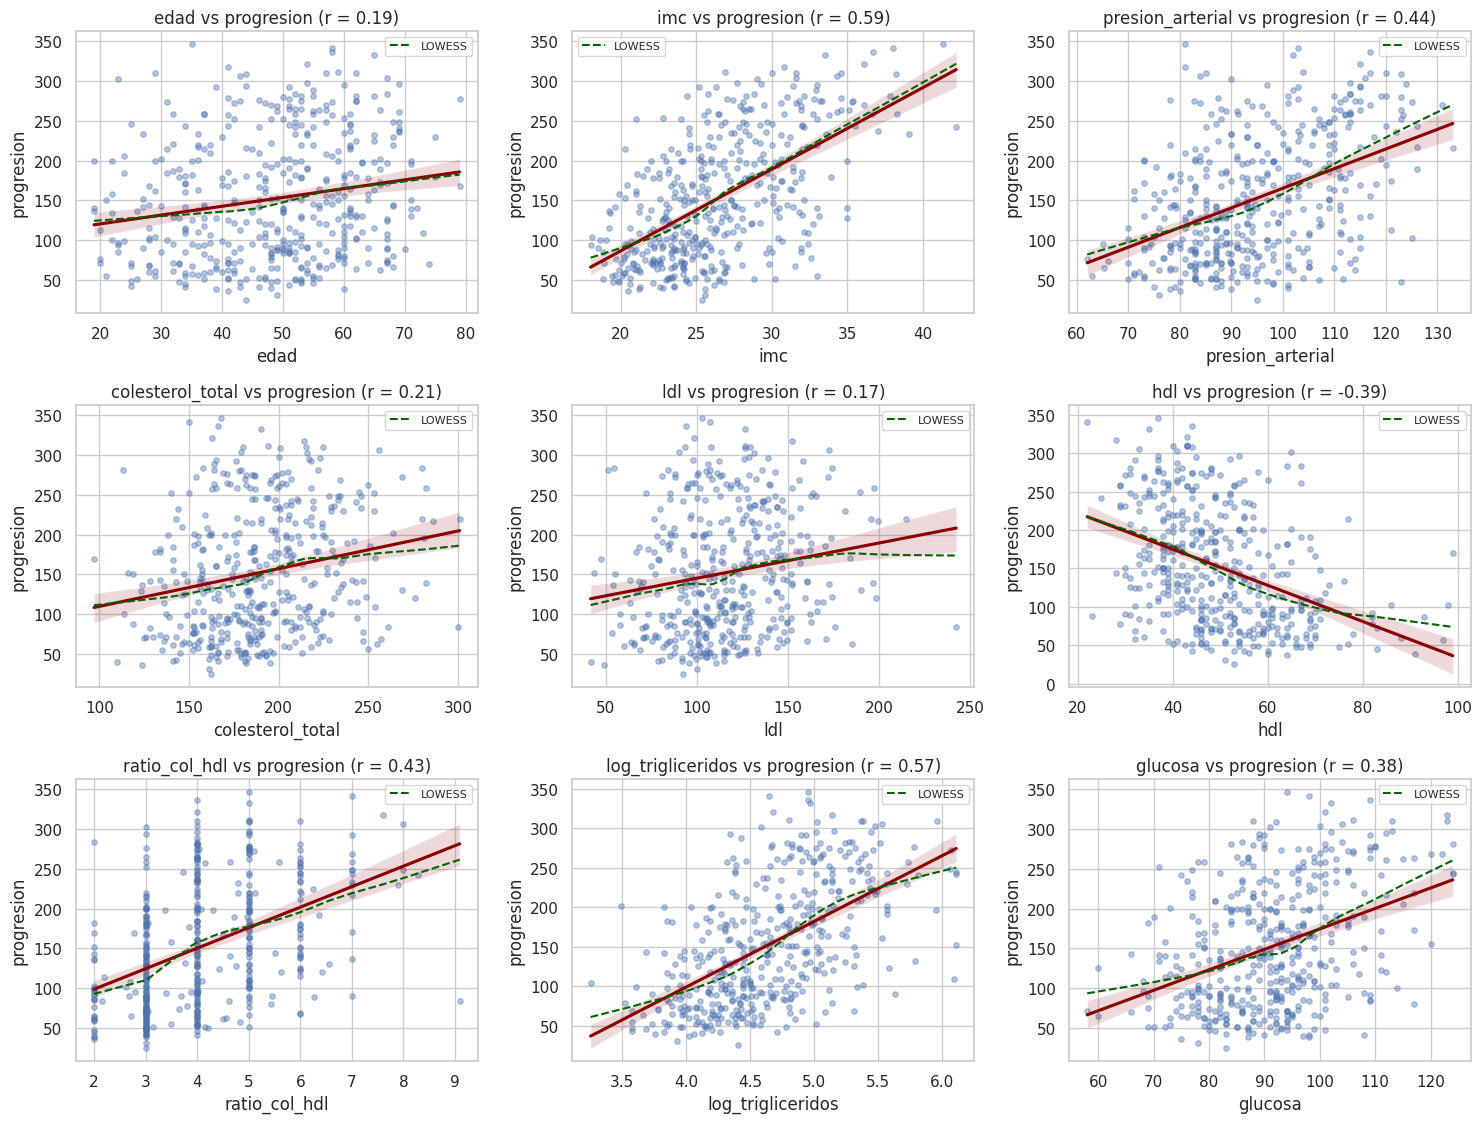

In [20]:
def graficar_bivariado_numerico(datos, columnas, objetivo, n_col=3):
    n = len(columnas)
    if n == 0:
        print("No hay predictores numéricos.")
        return
    n_fil = int(np.ceil(n / n_col))
    fig, ejes = plt.subplots(n_fil, n_col, figsize=(5 * n_col, 3.8 * n_fil), squeeze=False)
    for ax, col in zip(ejes.flat, columnas):
        sns.regplot(data=datos, x=col, y=objetivo, ax=ax,
                    scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "darkred"})
        suav = sm.nonparametric.lowess(datos[objetivo], datos[col], frac=0.6)
        ax.plot(suav[:, 0], suav[:, 1], color="darkgreen", ls="--", label="LOWESS")
        r = datos[[col, objetivo]].corr().iloc[0, 1]
        ax.set_title(f"{col} vs {objetivo} (r = {r:.2f})")
        ax.legend(loc="best", fontsize=8)
    for ax in list(ejes.flat)[n:]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

graficar_bivariado_numerico(df.dropna(subset=vars_numericas + [variable_objetivo]),
                            vars_numericas, variable_objetivo)

**Cómo leerlo:** si la línea LOWESS (verde) se aparta claramente de la recta (roja), la relación puede no ser lineal y conviene considerar transformaciones (log, cuadrado) o términos polinómicos. Una nube sin forma sugiere poca relación **marginal** (lo que no descarta un aporte cuando se controla por otras variables).

### Predictores categóricos frente a la respuesta

Se comparan las distribuciones de $Y$ por grupo mediante boxplots, violin plots y estadísticas por grupo.

**progresion según sexo**

,count,mean,median,std,min,max
sexo,,,,,,
Grupo_1,235,149.0213,140.0000,75.9058,25.0000,346.0000
Grupo_2,207,155.6667,141.0000,78.4533,39.0000,341.0000


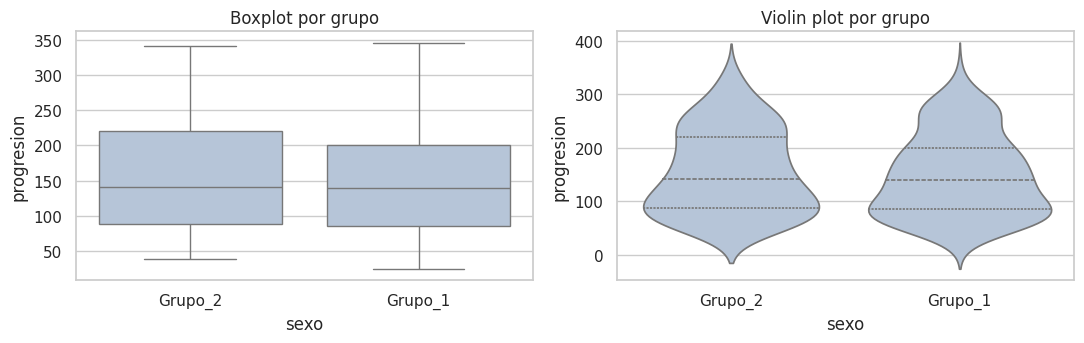

In [21]:
def bivariado_categorico(datos, columnas, objetivo):
    for col in columnas:
        display(Markdown(f"**{objetivo} según {col}**"))
        display(datos.groupby(col, observed=True)[objetivo]
                .agg(["count", "mean", "median", "std", "min", "max"]))
        fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
        sns.boxplot(data=datos, x=col, y=objetivo, ax=ejes[0], color="lightsteelblue")
        ejes[0].set_title("Boxplot por grupo")
        sns.violinplot(data=datos, x=col, y=objetivo, ax=ejes[1], color="lightsteelblue", inner="quartile")
        ejes[1].set_title("Violin plot por grupo")
        plt.tight_layout(); plt.show()

if vars_categoricas:
    bivariado_categorico(df, vars_categoricas, variable_objetivo)
else:
    print("No hay variables categóricas.")

## 4.6 Matriz de correlación

El **coeficiente de correlación de Pearson** $r \in [-1, 1]$ mide la intensidad de la relación **lineal** entre dos variables:

- **Signo:** positivo, ambas crecen juntas; negativo, una crece cuando la otra decrece.
- **Magnitud (orientativa):** $|r|<0.3$ débil; $0.3\le|r|<0.7$ moderada; $|r|\ge0.7$ fuerte.
- **Correlación con $Y$:** indica asociación **marginal** (sin controlar por otras variables).
- **Correlación entre predictores:** valores altos anticipan **multicolinealidad** (se confirma con el VIF, Parte 10).

> ⚠️ **Correlación no implica causalidad.** Además, la correlación **no debe ser el único criterio para seleccionar variables**: un predictor con baja correlación marginal puede ser relevante al controlar por otros, y uno muy correlacionado puede ser redundante.

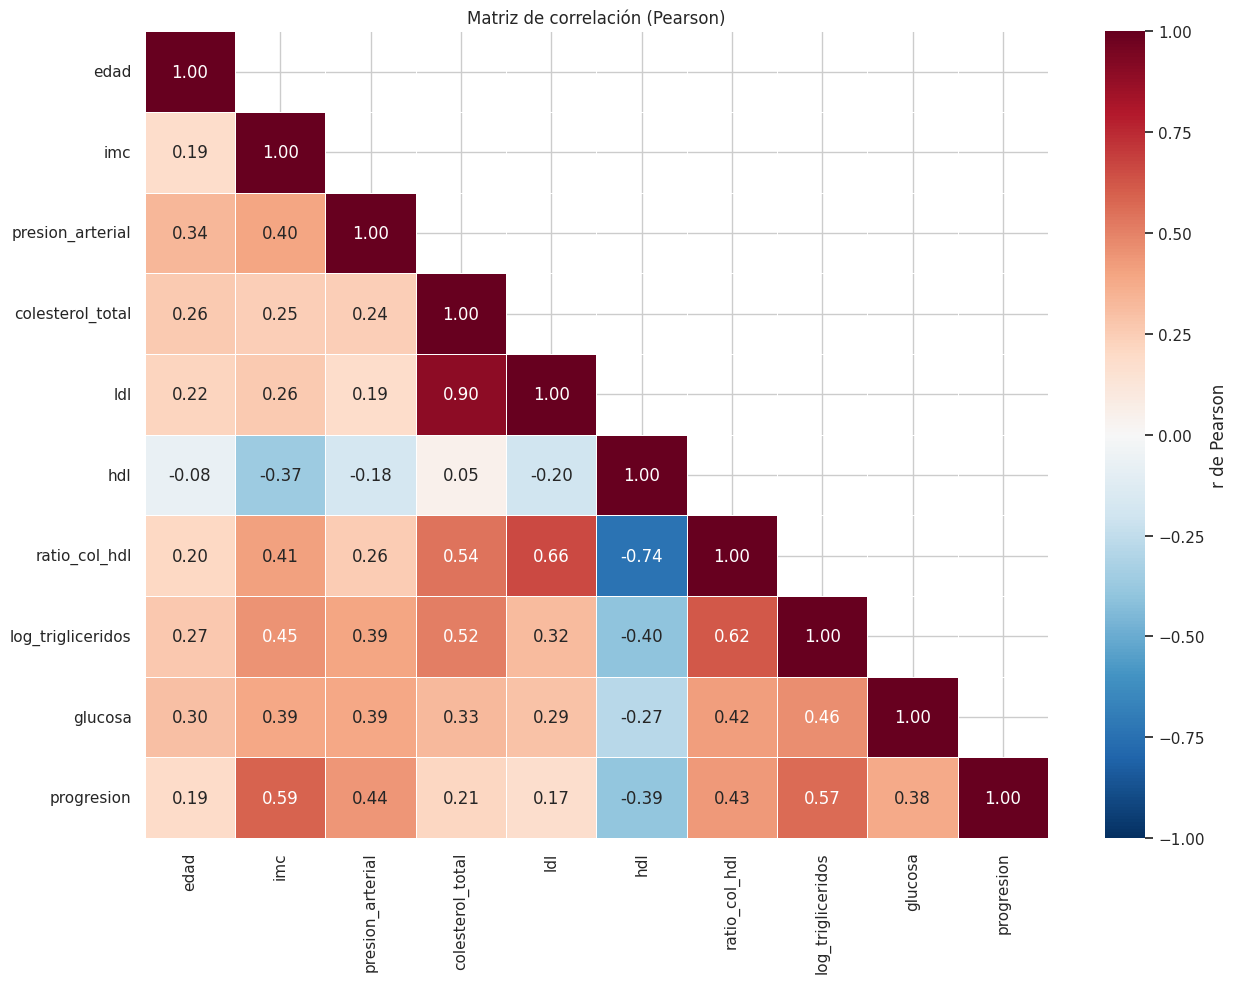

,r_con_Y,abs_r
imc,0.5865,0.5865
log_trigliceridos,0.5659,0.5659
presion_arterial,0.4415,0.4415
ratio_col_hdl,0.4305,0.4305
hdl,-0.3948,0.3948
glucosa,0.3825,0.3825
colesterol_total,0.2120,0.2120
edad,0.1879,0.1879
ldl,0.1741,0.1741


In [22]:
matriz_corr = df[cols_num_eda].corr(method="pearson")

mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(1.0 * len(cols_num_eda) + 3, 0.8 * len(cols_num_eda) + 2))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={"label": "r de Pearson"})
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

# Correlación de cada predictor con Y, ordenada por magnitud
corr_con_y = (matriz_corr[variable_objetivo].drop(variable_objetivo)
              .to_frame("r_con_Y").assign(abs_r=lambda t: t["r_con_Y"].abs())
              .sort_values("abs_r", ascending=False))
display(corr_con_y)

In [23]:
# Pares de predictores con correlación alta (posible multicolinealidad)
UMBRAL_CORR = 0.70   # ✏️ EDITAR si lo desea

pares_altos = []
for i, a in enumerate(vars_numericas):
    for b in vars_numericas[i + 1:]:
        r = matriz_corr.loc[a, b]
        if abs(r) >= UMBRAL_CORR:
            pares_altos.append({"variable_1": a, "variable_2": b, "r": r})
pares_altos = pd.DataFrame(pares_altos, columns=["variable_1", "variable_2", "r"])
print(f"Pares de predictores con |r| >= {UMBRAL_CORR}:")
display(pares_altos if len(pares_altos) else "Ninguno")

# Complemento: correlación de Spearman (monótona, robusta a atípicos)
display(Markdown("**Correlación de Spearman con Y** (útil si hay relaciones no lineales monótonas o atípicos)"))
display(df[cols_num_eda].corr(method="spearman")[variable_objetivo].drop(variable_objetivo)
        .sort_values(key=np.abs, ascending=False).to_frame("rho_Spearman"))

Pares de predictores con |r| >= 0.7:


,variable_1,variable_2,r
0,colesterol_total,ldl,0.8967
1,hdl,ratio_col_hdl,-0.7385


**Correlación de Spearman con Y** (útil si hay relaciones no lineales monótonas o atípicos)

,rho_Spearman
log_trigliceridos,0.5894
imc,0.5614
ratio_col_hdl,0.4489
presion_arterial,0.4162
hdl,-0.4100
glucosa,0.3508
colesterol_total,0.2324
edad,0.1978
ldl,0.1958


## 4.7 Pairplot (opcional)

Muestra simultáneamente todas las relaciones de a pares. Sólo es legible con **pocas variables**; por eso se grafican $Y$ y los predictores con mayor correlación absoluta con ella.

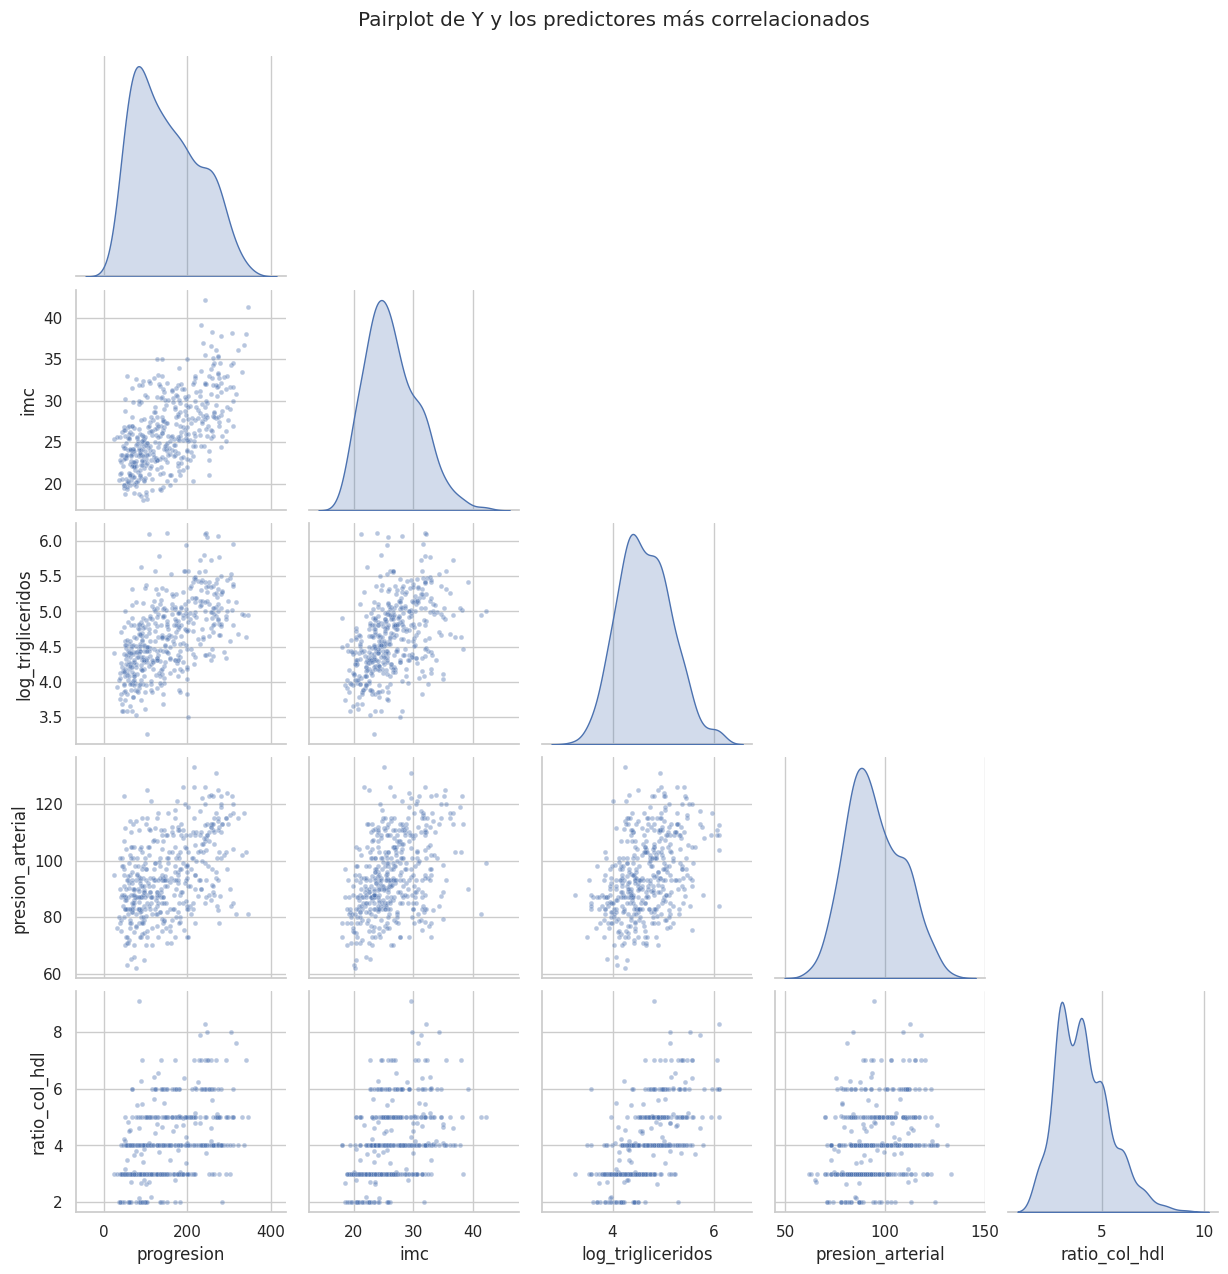

In [24]:
MAX_VARS_PAIRPLOT = 5   # ✏️ EDITAR (se recomienda no superar 6)
vars_pair = [variable_objetivo] + list(corr_con_y.index[:MAX_VARS_PAIRPLOT - 1])
g = sns.pairplot(df[vars_pair].dropna(), corner=True, diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Pairplot de Y y los predictores más correlacionados", y=1.02)
plt.show()

## 4.8 Síntesis del EDA

La celda siguiente resume **automáticamente** algunos hallazgos, como insumo para su interpretación (no la reemplaza).

In [25]:
print("=== SÍNTESIS AUTOMÁTICA DEL EDA (insumo para el estudiante) ===\n")
print(f"Observaciones: {len(df)} | Predictores candidatos: {len(candidatas)} "
      f"({len(vars_numericas)} numéricos, {len(vars_categoricas)} categóricos)")
print(f"Celdas faltantes totales: {int(df.isna().sum().sum())} | Filas duplicadas: {df.duplicated().sum()}")

top = corr_con_y.head(3)
print("\nPredictores numéricos con mayor |r| con Y:")
for var, fila in top.iterrows():
    print(f"  - {var}: r = {fila['r_con_Y']:.3f}")

asimetricas = tabla_descriptivos.index[tabla_descriptivos["asimetria"].abs() > 1].tolist()
print("\nVariables con |asimetría| > 1 (posible transformación):", asimetricas if asimetricas else "ninguna")

atipicos = {}
for c in cols_num_eda:
    s = df[c].dropna(); a, b = s.quantile([0.25, 0.75]); r = b - a
    atipicos[c] = int(((s < a - 1.5 * r) | (s > b + 1.5 * r)).sum())
print("Número de atípicos (regla 1.5·RIC) por variable:", {k: v for k, v in atipicos.items() if v > 0})

print(f"\nPares de predictores con |r| >= {UMBRAL_CORR}:",
      [f"{f.variable_1}-{f.variable_2} ({f.r:.2f})" for f in pares_altos.itertuples()] or "ninguno")

=== SÍNTESIS AUTOMÁTICA DEL EDA (insumo para el estudiante) ===

Observaciones: 442 | Predictores candidatos: 10 (9 numéricos, 1 categóricos)
Celdas faltantes totales: 0 | Filas duplicadas: 0

Predictores numéricos con mayor |r| con Y:
  - imc: r = 0.586
  - log_trigliceridos: r = 0.566
  - presion_arterial: r = 0.441

Variables con |asimetría| > 1 (posible transformación): ninguna
Número de atípicos (regla 1.5·RIC) por variable: {'imc': 3, 'colesterol_total': 8, 'ldl': 7, 'hdl': 7, 'ratio_col_hdl': 2, 'log_trigliceridos': 4, 'glucosa': 9}

Pares de predictores con |r| >= 0.7: ['colesterol_total-ldl (0.90)', 'hdl-ratio_col_hdl (-0.74)']


## ❓ Preguntas para el estudiante

1. ¿Qué variables parecen relacionadas con $Y$? ¿Con qué signo?
2. ¿Qué variables presentan distribuciones problemáticas (asimetría fuerte, concentración, pocos valores)?
3. ¿Existen *outliers*? ¿Son errores o valores plausibles?
4. ¿Hay predictores muy correlacionados entre sí? ¿Qué implicaciones tendría incluirlos juntos?
5. ¿Qué variables podrían requerir transformación (log, raíz, polinomio)?
6. ¿Qué variables no parecen aportar información?

*Respuestas:*

- ...

## 📝 Para el informe: análisis exploratorio

Incluya:

- tabla de descriptivos de las variables cuantitativas y de frecuencias de las categóricas;
- resultado del diagnóstico de calidad y las decisiones tomadas (con justificación);
- descripción específica de la variable respuesta (forma, asimetría, atípicos) con su histograma/boxplot;
- 2–4 gráficos bivariados relevantes (no todos);
- la matriz de correlación y el comentario sobre posibles problemas de multicolinealidad;
- una síntesis de hallazgos que motive los predictores que se llevarán al modelo.

---
# PARTE 5. Preparación de los datos

**¿Qué se hace?** Se define formalmente la matriz de predictores $X$ y el vector respuesta $y$, y se codifican las variables categóricas.

**¿Por qué?** Los modelos sólo aceptan números. Además, las decisiones de preparación deben ser explícitas y reproducibles.

## 5.1 Selección de predictores candidatos ✏️ EDITAR

Incluya sólo variables **conceptualmente razonables**: medidas antes o al mismo tiempo que $Y$, sin información "del futuro" y sin identificadores.

In [26]:
# ===============================================================
# ✏️ EDITAR: predictores candidatos (por defecto, todos los no excluidos)
# ===============================================================
predictores = list(candidatas)
# Ejemplo de selección manual:
# predictores = ["edad", "sexo", "imc", "presion_arterial", "hdl", "log_trigliceridos"]

pred_numericos = [c for c in predictores if c in vars_numericas]
pred_categoricos = [c for c in predictores if c in vars_categoricas]

# Observaciones sin valor en Y no pueden usarse para ajustar ni evaluar el modelo
n_sin_y = int(df[variable_objetivo].isna().sum())
datos_modelo = df.loc[df[variable_objetivo].notna(), predictores + [variable_objetivo]].copy()
print(f"Observaciones sin valor de Y (no utilizables): {n_sin_y}")
print(f"Observaciones disponibles para modelar: {len(datos_modelo)}")
print("Predictores numéricos  :", pred_numericos)
print("Predictores categóricos:", pred_categoricos)

Observaciones sin valor de Y (no utilizables): 0
Observaciones disponibles para modelar: 442
Predictores numéricos  : ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa']
Predictores categóricos: ['sexo']


## 5.2 Codificación dummy de variables categóricas

Una variable categórica con $k$ categorías se representa con $k-1$ variables **dummy** (0/1).

- La categoría omitida es la **categoría de referencia**: su efecto queda absorbido en el intercepto.
- Cada coeficiente dummy se interpreta como la **diferencia promedio en $Y$** entre esa categoría y la de referencia, manteniendo constantes las demás variables.
- **Trampa de las variables dummy:** si se incluyen las $k$ dummies junto con el intercepto, las columnas suman 1 (igual a la constante) y hay **colinealidad perfecta**: $\mathbf{X}^\top\mathbf{X}$ no es invertible. Por eso se usa `drop_first=True`.

Por defecto la referencia es la primera categoría en orden alfabético; puede cambiarse reordenando el diccionario `categorias`.

> **¿Hay fuga de información (*data leakage*)?** La codificación dummy no estima ningún parámetro a partir de los datos (sólo usa la lista de categorías posibles), por lo que puede hacerse antes de dividir. En cambio, **imputar**, **estandarizar** o **seleccionar variables** sí aprenden de los datos y deben hacerse **sólo con el conjunto de entrenamiento**.

In [27]:
# Categorías posibles de cada variable categórica (la primera será la referencia)
categorias = {c: sorted(datos_modelo[c].dropna().unique().tolist()) for c in pred_categoricos}
# ✏️ EDITAR para cambiar la referencia, p. ej.: categorias["sexo"] = ["Grupo_2", "Grupo_1"]


def codificar_predictores(datos, cols_numericas, cols_categoricas, categorias):
    """Devuelve la matriz numérica de predictores con dummies k-1 (drop_first=True).

    Usa siempre las mismas categorías, de modo que nuevos datos (prueba o casos
    nuevos) quedan con exactamente las mismas columnas que el entrenamiento.
    """
    datos = datos[cols_numericas + cols_categoricas].copy()
    for c in cols_categoricas:
        datos[c] = pd.Categorical(datos[c], categories=categorias[c])
    codificada = pd.get_dummies(datos, columns=cols_categoricas, drop_first=True, dtype=float)
    # Si la categoría original falta, sus dummies quedan como NaN (no como 0), para que
    # el faltante no se confunda con la categoría de referencia y pueda imputarse después.
    for c in cols_categoricas:
        columnas_c = [k for k in codificada.columns if k.startswith(f"{c}_") and k not in cols_numericas]
        codificada.loc[datos[c].isna(), columnas_c] = np.nan
    return codificada


X = codificar_predictores(datos_modelo, pred_numericos, pred_categoricos, categorias)
y = datos_modelo[variable_objetivo].astype(float)

for c in pred_categoricos:
    print(f"'{c}': categoría de referencia = '{categorias[c][0]}'")
print(f"\nMatriz X: {X.shape[0]} filas x {X.shape[1]} columnas")
display(X.head())

'sexo': categoría de referencia = 'Grupo_1'

Matriz X: 442 filas x 10 columnas


,edad,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,sexo_Grupo_2
0,59.0000,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000,1.0000
1,48.0000,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000,0.0000
2,72.0000,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000,1.0000
3,24.0000,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000,0.0000
4,50.0000,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000,0.0000


## 5.3 Valores faltantes en los predictores

Si hay faltantes, existen varias alternativas: eliminar filas (análisis de casos completos), imputar (media, mediana, moda o métodos más avanzados) o excluir la variable. Cada una tiene costos:

- Eliminar filas reduce $n$ y puede sesgar si los faltantes no son aleatorios.
- Imputar con la mediana es simple, pero reduce artificialmente la variabilidad.

En este cuadernillo, si hay faltantes, se **imputa con la mediana calculada sólo en entrenamiento** (Parte 6) para evitar fuga de información. Documente esta decisión en el informe.

In [28]:
faltantes_X = X.isna().sum()
print("Faltantes en X por columna:")
display(faltantes_X[faltantes_X > 0].to_frame("n") if faltantes_X.sum() else "Ninguno")

Faltantes en X por columna:


'Ninguno'

---
# PARTE 6. División entrenamiento-prueba

**¿Qué se hace?** Se separan los datos en un conjunto de **entrenamiento** (80%) y uno de **prueba** (20%).

**¿Por qué?**

- **Entrenamiento:** se usa para explorar modelos, seleccionar variables, elegir hiperparámetros y estimar coeficientes.
- **Prueba:** simula datos nuevos. Se usa **al final** para estimar honestamente la capacidad predictiva.
- **Reproducibilidad:** `random_state=123` garantiza que la partición sea la misma en cada ejecución.

> ⚠️ Si se vuelve una y otra vez al conjunto de prueba para decidir qué variables incluir o qué modelo elegir, el conjunto de prueba **deja de ser independiente** y el error reportado será optimista. Para comparar modelos durante el desarrollo se usa **validación cruzada dentro del entrenamiento**.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print(f"Entrenamiento: {X_train.shape[0]} observaciones | Prueba: {X_test.shape[0]} observaciones")
display(pd.DataFrame({"entrenamiento": y_train.describe(), "prueba": y_test.describe()}).T)

Entrenamiento: 353 observaciones | Prueba: 89 observaciones


,count,mean,std,min,25%,50%,75%,max
entrenamiento,353.0000,152.4278,76.5028,25.0000,88.0000,141.0000,209.0000,346.0000
prueba,89.0000,150.9663,79.8233,31.0000,80.0000,140.0000,214.0000,336.0000


**Interpretación:** las distribuciones de $Y$ en entrenamiento y prueba deberían ser similares (medias y desviaciones parecidas). Diferencias grandes pueden indicar una partición poco representativa (frecuente con muestras pequeñas).

### Imputación sin fuga de información

Las medianas se calculan **sólo con entrenamiento** y se aplican a ambos conjuntos.

In [30]:
medianas_train = X_train.median()
n_imputados_train = int(X_train.isna().sum().sum())
n_imputados_test = int(X_test.isna().sum().sum())
X_train = X_train.fillna(medianas_train)
X_test = X_test.fillna(medianas_train)
print(f"Celdas imputadas con la mediana de entrenamiento -> train: {n_imputados_train}, test: {n_imputados_test}")

Celdas imputadas con la mediana de entrenamiento -> train: 0, test: 0


### Funciones auxiliares reutilizables

Se definen aquí funciones que se usarán en el resto del cuadernillo:

- `con_constante(X)`: agrega la columna del intercepto (`const`) que requiere `statsmodels`.
- `ajustar_ols(X, y, variables)`: ajusta un modelo OLS con las variables indicadas.
- `metricas_regresion(y_real, y_pred, p)`: calcula $R^2$, $R^2$ ajustado, MAE, MSE y RMSE.
- `rmse_cv(X, y, variables)`: RMSE promedio por validación cruzada de un OLS (sólo con entrenamiento).

In [31]:
def con_constante(X_):
    """Agrega la columna 'const' (intercepto) siempre, aunque exista una columna constante."""
    return sm.add_constant(X_, has_constant="add")


def ajustar_ols(X_, y_, variables=None):
    """Ajusta un OLS de statsmodels con las variables indicadas (todas si variables=None)."""
    variables = list(X_.columns) if variables is None else list(variables)
    return sm.OLS(y_, con_constante(X_[variables])).fit()


def metricas_regresion(y_real, y_pred, p=None):
    """Métricas de ajuste/predicción. p = número de predictores (para R² ajustado)."""
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_real)
    mse = mean_squared_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    salida = {"R2": r2}
    if p is not None and n - p - 1 > 0:
        salida["R2_ajustado"] = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    salida.update({"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse)})
    return {k: float(v) for k, v in salida.items()}


def rmse_cv(X_, y_, variables=None, cv=None):
    """RMSE por validación cruzada de una regresión lineal OLS (sin penalización)."""
    variables = list(X_.columns) if variables is None else list(variables)
    cv = kf if cv is None else cv
    puntajes = cross_val_score(LinearRegression(), X_[variables], y_, cv=cv,
                               scoring="neg_root_mean_squared_error")
    return -puntajes

---
# PARTE 7. Modelo lineal múltiple completo

**¿Qué se hace?** Se ajusta por OLS un modelo con **todos** los predictores candidatos, usando sólo el conjunto de entrenamiento.

**¿Por qué?** Es el punto de partida: muestra la contribución de cada variable controlando por las demás, y sirve de referencia para comparar modelos reducidos.

**¿Cómo leer `summary()`?**

| Elemento | Significado |
|---|---|
| `coef` | Estimación $\hat\beta_j$. `const` es el intercepto $\hat\beta_0$. |
| `std err` | Error estándar: incertidumbre de la estimación. |
| `t` | $t = \hat\beta_j / SE(\hat\beta_j)$. Contrasta $H_0:\beta_j=0$. |
| `P>|t|` | p-valor. Si $< \alpha$, se rechaza $H_0$: hay evidencia de asociación **controlando por las demás variables**. |
| `[0.025 0.975]` | Intervalo de confianza del 95% para $\beta_j$. Si no contiene el 0, coincide con $p<0.05$. |
| `R-squared` | $R^2 = 1 - SSE/SST$: proporción de la variabilidad de $Y$ explicada. Siempre aumenta al agregar variables. |
| `Adj. R-squared` | $R^2_{aj} = 1-(1-R^2)\frac{n-1}{n-p-1}$: penaliza el número de predictores. |
| `F-statistic`, `Prob (F-statistic)` | Prueba global $H_0:\beta_1=\dots=\beta_p=0$. Un p-valor pequeño indica que el modelo, en conjunto, explica más que la media. |
| `AIC`, `BIC` | Criterios de información: $AIC = -2\ln L + 2k$, $BIC = -2\ln L + k\ln n$. Menor es mejor; BIC penaliza más la complejidad. |
| `Durbin-Watson`, `Jarque-Bera`, `Cond. No.` | Diagnósticos de autocorrelación, normalidad y colinealidad (se analizan en las Partes 10 y 15). |

In [32]:
X_train_sm = sm.add_constant(X_train)

modelo_completo = sm.OLS(
    y_train,
    X_train_sm
).fit()

modelo_completo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             progresion   R-squared:                       0.502
Model:                            OLS   Adj. R-squared:                  0.487
Method:                 Least Squares   F-statistic:                     34.41
Date:                Fri, 25 Sep 2026   Prob (F-statistic):           4.80e-46
Time:                        16:58:24   Log-Likelihood:                -1908.6
No. Observations:                 353   AIC:                             3839.
Df Residuals:                     342   BIC:                             3882.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -342.5560     73.205     -4.679      0.000    -486.545    -198.567
edad                 -0.0225      0.247     -0.091      0.927      -0.508       0.463
imc                   5.4451      0.794      6.861      0.000       3.884       7.006
presion_arterial      1.0177      0.250      4.079      0.000       0.527       1.509
colesterol_total     -1.1366      0.626     -1.815      0.070      -2.368       0.095
ldl                   0.7311      0.582      1.257      0.210      -0.413       1.875
hdl                   0.4814      0.849      0.567      0.571      -1.188       2.150
ratio_col_hdl         9.3343      6.694      1.394      0.164      -3.833      22.502
log_trigliceridos    62.9963     17.294      3.643      0.000      28.980      97.013
glucosa               0.4606      0.305      1.510      0.132      -0.139       1.061
sexo_Grupo_2        -21.4695      6.627     -3.240      0.001     -34.505      -8.434
==============================================================================
Omnibus:                        1.011   Durbin-Watson:                   2.250
Prob(Omnibus):                  0.603   Jarque-Bera (JB):                1.031
Skew:                          -0.016   Prob(JB):                        0.597
Kurtosis:                       2.737   Cond. No.                     6.92e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.92e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Tabla de coeficientes reutilizable

Para el informe es más práctico una tabla limpia con coeficientes, errores estándar, estadístico t, p-valor e intervalos de confianza.

In [33]:
def tabla_coeficientes(modelo, alpha=ALPHA):
    ic = modelo.conf_int(alpha=alpha)
    tabla = pd.DataFrame({
        "coeficiente": modelo.params, "error_estandar": modelo.bse,
        "t": modelo.tvalues, "p_valor": modelo.pvalues,
        f"IC_{int((1 - alpha) * 100)}%_inf": ic[0], f"IC_{int((1 - alpha) * 100)}%_sup": ic[1],
    })
    tabla["significativo"] = np.where(tabla["p_valor"] < alpha, "sí", "no")
    return tabla


def resumen_global(modelo):
    return pd.Series({
        "n": int(modelo.nobs), "p (predictores)": int(modelo.df_model),
        "R2": modelo.rsquared, "R2_ajustado": modelo.rsquared_adj,
        "F": modelo.fvalue, "p_valor_F": modelo.f_pvalue,
        "AIC": modelo.aic, "BIC": modelo.bic,
        "sigma_residual": np.sqrt(modelo.scale),
    })

display(tabla_coeficientes(modelo_completo))
display(resumen_global(modelo_completo).to_frame("modelo completo"))

,coeficiente,error_estandar,t,p_valor,IC_95%_inf,IC_95%_sup,significativo
const,-342.5560,73.2049,-4.6794,0.0000,-486.5446,-198.5675,sí
edad,-0.0225,0.2466,-0.0911,0.9275,-0.5076,0.4626,no
imc,5.4451,0.7936,6.8609,0.0000,3.8841,7.0062,sí
presion_arterial,1.0177,0.2495,4.0786,0.0001,0.5269,1.5086,sí
colesterol_total,-1.1366,0.6262,-1.8150,0.0704,-2.3684,0.0952,no
ldl,0.7311,0.5815,1.2572,0.2096,-0.4127,1.8749,no
hdl,0.4814,0.8485,0.5673,0.5709,-1.1876,2.1503,no
ratio_col_hdl,9.3343,6.6944,1.3943,0.1641,-3.8331,22.5018,no
log_trigliceridos,62.9963,17.2942,3.6426,0.0003,28.9799,97.0128,sí
glucosa,0.4606,0.3051,1.5097,0.1320,-0.1395,1.0608,no


,modelo completo
n,353.0000
p (predictores),10.0000
R2,0.5016
R2_ajustado,0.4870
F,34.4129
p_valor_F,0.0000
AIC,"3,839.1441"
BIC,"3,881.6753"
sigma_residual,54.7956


### Alternativa equivalente con fórmulas (`statsmodels.formula.api`)

La interfaz de fórmulas (estilo R) produce el mismo modelo. Es cómoda para escribir modelos a mano, incluir transformaciones como `np.log(x)` o interacciones `x1:x2`. Se construye la fórmula automáticamente a partir de las columnas de entrenamiento.

In [34]:
datos_train = X_train.assign(**{variable_objetivo: y_train})
formula_completa = f"Q('{variable_objetivo}') ~ " + " + ".join(f"Q('{c}')" for c in X_train.columns)
print(formula_completa)

modelo_formula = smf.ols(formula_completa, data=datos_train).fit()
print("\n¿Coinciden los coeficientes con sm.OLS?",
      np.allclose(modelo_formula.params.values, modelo_completo.params.values))

Q('progresion') ~ Q('edad') + Q('imc') + Q('presion_arterial') + Q('colesterol_total') + Q('ldl') + Q('hdl') + Q('ratio_col_hdl') + Q('log_trigliceridos') + Q('glucosa') + Q('sexo_Grupo_2')

¿Coinciden los coeficientes con sm.OLS? True


## ❓ Preguntas para el estudiante

1. ¿El modelo es globalmente significativo (prueba F)?
2. ¿Qué proporción de la variabilidad de $Y$ explica? ¿Cuánto cambia al pasar de $R^2$ a $R^2$ ajustado?
3. ¿Qué coeficientes son significativos al 5%? ¿Tienen el signo esperado según la teoría?
4. ¿Hay coeficientes con signo contrario al esperado o con errores estándar muy grandes? (Posible multicolinealidad.)

---
# PARTE 8. Interpretación de coeficientes

El coeficiente $\beta_j$ representa el **cambio esperado en $Y$ ante un aumento de una unidad en $X_j$, manteniendo constantes las demás variables** del modelo (*ceteris paribus*).

- **Predictor numérico:** "Controlando por las demás variables del modelo, un incremento de una unidad en $X_1$ se asocia con un cambio promedio de $\beta_1$ unidades en $Y$."
- **Predictor dummy:** "Controlando por las demás variables, la categoría A presenta, en promedio, $\beta$ unidades más (o menos) de $Y$ que la categoría de referencia."
- **Intercepto:** valor esperado de $Y$ cuando todos los predictores valen 0; muchas veces no tiene interpretación práctica (p. ej., edad = 0 e IMC = 0).

> ⚠️ **Asociación no es causalidad.** Con datos observacionales, use verbos como *se asocia*, *se relaciona*, *está vinculado*; evite *causa*, *produce*, *provoca*, salvo que el diseño (experimento aleatorizado, diseño cuasi-experimental) lo respalde.

La siguiente función **redacta** interpretaciones a partir de los coeficientes estimados. Úsela como borrador y ajuste la redacción a las unidades reales de sus variables.

In [35]:
def interpretar_coeficientes(modelo, nombre_y, variables_dummy=None, alpha=ALPHA):
    """Genera frases de interpretación a partir de un modelo OLS ajustado."""
    variables_dummy = variables_dummy or []
    frases = []
    for var in modelo.params.index:
        b, p = modelo.params[var], modelo.pvalues[var]
        sig = (f"estadísticamente significativo (p = {p:.4f})" if p < alpha
               else f"no significativo al {int(alpha * 100)}% (p = {p:.4f})")
        if var == "const":
            frases.append(f"- **Intercepto:** valor esperado de {nombre_y} cuando todos los predictores "
                          f"valen 0: {b:.4f}. Evalúe si ese escenario tiene sentido.")
        elif var in variables_dummy:
            direccion = "mayor" if b > 0 else "menor"
            frases.append(f"- **{var}:** controlando por las demás variables, esta categoría presenta en "
                          f"promedio un valor de {nombre_y} {abs(b):.4f} unidades {direccion} que la categoría "
                          f"de referencia; {sig}.")
        else:
            direccion = "aumento" if b > 0 else "disminución"
            frases.append(f"- **{var}:** controlando por las demás variables del modelo, un incremento de una "
                          f"unidad en {var} se asocia con una {direccion} promedio de {abs(b):.4f} unidades "
                          f"en {nombre_y}; {sig}.")
    return "\n".join(frases)

columnas_dummy = [c for c in X.columns if c not in pred_numericos]
display(Markdown(interpretar_coeficientes(modelo_completo, variable_objetivo, columnas_dummy)))

- **Intercepto:** valor esperado de progresion cuando todos los predictores valen 0: -342.5560. Evalúe si ese escenario tiene sentido.
- **edad:** controlando por las demás variables del modelo, un incremento de una unidad en edad se asocia con una disminución promedio de 0.0225 unidades en progresion; no significativo al 5% (p = 0.9275).
- **imc:** controlando por las demás variables del modelo, un incremento de una unidad en imc se asocia con una aumento promedio de 5.4451 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **presion_arterial:** controlando por las demás variables del modelo, un incremento de una unidad en presion_arterial se asocia con una aumento promedio de 1.0177 unidades en progresion; estadísticamente significativo (p = 0.0001).
- **colesterol_total:** controlando por las demás variables del modelo, un incremento de una unidad en colesterol_total se asocia con una disminución promedio de 1.1366 unidades en progresion; no significativo al 5% (p = 0.0704).
- **ldl:** controlando por las demás variables del modelo, un incremento de una unidad en ldl se asocia con una aumento promedio de 0.7311 unidades en progresion; no significativo al 5% (p = 0.2096).
- **hdl:** controlando por las demás variables del modelo, un incremento de una unidad en hdl se asocia con una aumento promedio de 0.4814 unidades en progresion; no significativo al 5% (p = 0.5709).
- **ratio_col_hdl:** controlando por las demás variables del modelo, un incremento de una unidad en ratio_col_hdl se asocia con una aumento promedio de 9.3343 unidades en progresion; no significativo al 5% (p = 0.1641).
- **log_trigliceridos:** controlando por las demás variables del modelo, un incremento de una unidad en log_trigliceridos se asocia con una aumento promedio de 62.9963 unidades en progresion; estadísticamente significativo (p = 0.0003).
- **glucosa:** controlando por las demás variables del modelo, un incremento de una unidad en glucosa se asocia con una aumento promedio de 0.4606 unidades en progresion; no significativo al 5% (p = 0.1320).
- **sexo_Grupo_2:** controlando por las demás variables, esta categoría presenta en promedio un valor de progresion 21.4695 unidades menor que la categoría de referencia; estadísticamente significativo (p = 0.0013).

### Magnitud relativa: coeficientes estandarizados

Los coeficientes en unidades originales **no son comparables entre sí** (una unidad de edad no equivale a una unidad de colesterol). Para comparar la importancia relativa se pueden usar **coeficientes estandarizados**: $\beta_j^{*} = \beta_j \cdot s_{X_j}/s_Y$, es decir, el cambio en desviaciones estándar de $Y$ por una desviación estándar de $X_j$.

In [36]:
def coeficientes_estandarizados(modelo, X_, y_):
    b = modelo.params.drop("const")
    return (b * X_[b.index].std() / y_.std()).to_frame("beta_estandarizado") \
        .assign(abs_beta=lambda t: t["beta_estandarizado"].abs()) \
        .sort_values("abs_beta", ascending=False)

display(coeficientes_estandarizados(modelo_completo, X_train, y_train))

,beta_estandarizado,abs_beta
colesterol_total,-0.5224,0.5224
log_trigliceridos,0.4335,0.4335
imc,0.3183,0.3183
ldl,0.2935,0.2935
presion_arterial,0.1845,0.1845
ratio_col_hdl,0.1607,0.1607
sexo_Grupo_2,-0.1403,0.1403
hdl,0.0838,0.0838
glucosa,0.0710,0.0710
edad,-0.0038,0.0038


## 📝 Para el informe

Reporte la tabla de coeficientes (coeficiente, error estándar, p-valor, IC 95%) y redacte la interpretación de **al menos** los coeficientes significativos, en las unidades reales de las variables y sin lenguaje causal.

---
# PARTE 9. Construcción automática de la ecuación

**¿Qué se hace?** Se convierte el vector de coeficientes en una ecuación legible, en texto y en LaTeX.

**¿Por qué?** El informe debe presentar el modelo como ecuación estimada: $\hat{Y} = \hat\beta_0 + \hat\beta_1X_1 + \dots + \hat\beta_pX_p$.

In [37]:
def ecuacion_modelo(coeficientes, nombre_y="Y", decimales=4, intercepto="const"):
    """Devuelve (texto, latex) de la ecuación estimada a partir de una Serie de coeficientes."""
    coef = pd.Series(coeficientes, dtype=float)
    b0 = coef.get(intercepto, 0.0)
    otros = coef.drop(intercepto, errors="ignore")
    texto = f"{nombre_y}_estimado = {b0:.{decimales}f}"
    latex_y = nombre_y.replace("_", r"\_")
    latex = rf"\widehat{{\text{{{latex_y}}}}} = {b0:.{decimales}f}"
    for var, b in otros.items():
        signo = "+" if b >= 0 else "-"
        texto += f" {signo} {abs(b):.{decimales}f}*{var}"
        var_tex = var.replace("_", r"\_")
        latex += rf" {signo} {abs(b):.{decimales}f}\,\text{{{var_tex}}}"
    return texto, latex

ec_texto, ec_latex = ecuacion_modelo(modelo_completo.params, variable_objetivo, decimales=3)
print(ec_texto)
display(Math(ec_latex))

progresion_estimado = -342.556 - 0.022*edad + 5.445*imc + 1.018*presion_arterial - 1.137*colesterol_total + 0.731*ldl + 0.481*hdl + 9.334*ratio_col_hdl + 62.996*log_trigliceridos + 0.461*glucosa - 21.470*sexo_Grupo_2


<IPython.core.display.Math object>

> La misma función sirve para cualquier modelo: basta pasarle `modelo.params` (statsmodels) o una Serie con los coeficientes (por ejemplo, los de Ridge o Lasso llevados a la escala original, Parte 12).

---
# PARTE 10. Multicolinealidad

**¿Qué es?** Hay multicolinealidad cuando uno o varios predictores pueden explicarse (casi) linealmente a partir de otros.

**¿Por qué importa?** No sesga las predicciones, pero **infla los errores estándar** de los coeficientes, vuelve inestables sus signos y magnitudes y dificulta la interpretación individual.

**Factor de Inflación de la Varianza (VIF):**

$$
VIF_j = \frac{1}{1-R_j^2}
$$

donde $R_j^2$ es el $R^2$ de regresar $X_j$ sobre los demás predictores. Guía **orientativa**:

| VIF | Lectura |
|---|---|
| ≈ 1 | Baja colinealidad |
| > 5 | Revisar |
| > 10 | Posible problema importante |

> Estas **no son reglas absolutas**. No elimine una variable **sólo** por su VIF: considere su importancia conceptual, si es una variable de control necesaria, o alternativas como combinar variables, centrarlas (en polinomios/interacciones) o usar Ridge.

In [38]:
def calcular_vif(X_):
    """VIF de cada predictor (se calcula con intercepto, que no se reporta)."""
    Xc = con_constante(X_)
    vif = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    tabla = pd.DataFrame({"Variable": X_.columns, "VIF": vif})
    tabla["lectura"] = pd.cut(tabla["VIF"], bins=[0, 5, 10, np.inf],
                              labels=["baja/moderada", "revisar (>5)", "posible problema (>10)"])
    return tabla.sort_values("VIF", ascending=False).reset_index(drop=True)

tabla_vif_completo = calcular_vif(X_train)
display(tabla_vif_completo)
print(f"Número de condición del modelo completo: {modelo_completo.condition_number:,.1f}")

,Variable,VIF,lectura
0,colesterol_total,56.8414,posible problema (>10)
1,ldl,37.4028,posible problema (>10)
2,hdl,14.9555,posible problema (>10)
3,log_trigliceridos,9.7186,revisar (>5)
4,ratio_col_hdl,9.1085,revisar (>5)
5,glucosa,1.5191,baja/moderada
6,imc,1.4770,baja/moderada
7,presion_arterial,1.4034,baja/moderada
8,sexo_Grupo_2,1.2871,baja/moderada
9,edad,1.2101,baja/moderada


Número de condición del modelo completo: 6,920.1


**Interpretación guiada:**

- Identifique las variables con VIF > 5 y relaciónelas con los pares muy correlacionados de la Parte 4.6.
- En la base de ejemplo, las mediciones séricas relacionadas entre sí (colesterol total, LDL, HDL y su razón) tienden a mostrar VIF altos porque unas se construyen o dependen de las otras: es un caso típico de colinealidad **estructural**.
- El número de condición alto también alerta sobre colinealidad, aunque depende de la escala de las variables.

## 📝 Para el informe

Presente la tabla de VIF, señale las variables problemáticas y explique qué decisión tomó (mantener, eliminar, combinar o usar regularización) y por qué.

---
# PARTE 11. Selección de variables

**¿Qué se hace?** Se buscan subconjuntos de predictores que expliquen $Y$ de forma **parsimoniosa** (con la menor complejidad razonable).

**¿Por qué?** Un modelo con demasiadas variables puede sobreajustar, ser inestable por multicolinealidad y difícil de interpretar; uno con muy pocas puede omitir variables relevantes y producir coeficientes sesgados.

> Todos los procedimientos de esta parte se aplican **sólo al conjunto de entrenamiento**.

## 11.1 Selección conceptual

Los métodos automáticos son **herramientas de apoyo, no sustitutos del criterio del analista**. Antes de ejecutarlos, considere:

| Criterio | Pregunta orientadora |
|---|---|
| Conocimiento del problema | ¿Hay una razón sustantiva para que la variable se relacione con $Y$? |
| Literatura | ¿Estudios previos la incluyen como determinante o variable de control? |
| Plausibilidad | ¿El signo esperado es coherente con la teoría? |
| Medición | ¿Está bien medida? ¿Tiene errores o escalas dudosas? |
| Calidad | ¿Tiene muchos faltantes, poca variabilidad, categorías escasas? |
| Disponibilidad | ¿Estará disponible cuando se quiera usar el modelo para predecir? |

Limitaciones conocidas de la selección automática por p-valores: los p-valores del modelo final quedan **sesgados a la baja** (se eligieron por ser pequeños), los resultados pueden cambiar con pequeñas variaciones en los datos, y el método puede excluir variables de control importantes.

## 11.2 Backward Elimination (eliminación hacia atrás)

**Algoritmo:**

1. Ajustar el modelo con todas las variables.
2. Identificar la variable con **mayor p-valor**.
3. Si ese p-valor es $\ge \alpha$, eliminarla y volver al paso 1.
4. Si todos los p-valores son $< \alpha$, detenerse.

In [39]:
def seleccion_backward(X_, y_, alpha=0.05, verbose=True):
    """Eliminación hacia atrás por p-valor. Devuelve (variables, historial)."""
    variables = list(X_.columns)
    historial = []
    paso = 0
    while variables:
        modelo = ajustar_ols(X_, y_, variables)
        p_valores = modelo.pvalues.drop("const")
        candidata, p_max = p_valores.idxmax(), p_valores.max()
        if p_max < alpha:
            if verbose:
                print(f"Fin: todas las variables tienen p < {alpha}.")
            break
        paso += 1
        variables.remove(candidata)
        historial.append({"paso": paso, "variable_sale": candidata, "p_valor": p_max,
                          "R2_aj_despues": ajustar_ols(X_, y_, variables).rsquared_adj if variables else np.nan,
                          "variables_restantes": ", ".join(variables)})
        if verbose:
            print(f"Paso {paso}: sale '{candidata}' (p = {p_max:.4f}). Restantes: {variables}")
    return variables, pd.DataFrame(historial)


seleccion_backward_vars, hist_backward = seleccion_backward(X_train, y_train, alpha=ALPHA)
print("\nVariables seleccionadas (Backward):", seleccion_backward_vars)
display(hist_backward)

Paso 1: sale 'edad' (p = 0.9275). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 2: sale 'hdl' (p = 0.5729). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ldl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 3: sale 'ldl' (p = 0.2120). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 4: sale 'glucosa' (p = 0.1210). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']
Fin: todas las variables tienen p < 0.05.

Variables seleccionadas (Backward): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']


,paso,variable_sale,p_valor,R2_aj_despues,variables_restantes
0,1,edad,0.9275,0.4885,"imc, presion_arterial, colesterol_total, ldl, ..."
1,2,hdl,0.5729,0.4895,"imc, presion_arterial, colesterol_total, ldl, ..."
2,3,ldl,0.2120,0.4886,"imc, presion_arterial, colesterol_total, ratio..."
3,4,glucosa,0.1210,0.4865,"imc, presion_arterial, colesterol_total, ratio..."


## 11.3 Forward Selection (selección hacia adelante)

**Algoritmo:**

1. Partir del modelo nulo (sólo intercepto).
2. Probar agregar, una por una, cada variable no incluida; registrar su p-valor en el modelo ampliado.
3. Si el menor p-valor es $< \alpha$, agregar esa variable.
4. Repetir hasta que ninguna variable nueva tenga $p < \alpha$.

Se reporta la **mejora en $R^2$ ajustado** en cada paso.

In [40]:
def seleccion_forward(X_, y_, alpha=0.05, verbose=True):
    """Selección hacia adelante por p-valor. Devuelve (variables, historial)."""
    seleccionadas, restantes = [], list(X_.columns)
    historial, r2aj_actual, paso = [], 0.0, 0
    while restantes:
        p_vals, r2aj = {}, {}
        for var in restantes:
            m = ajustar_ols(X_, y_, seleccionadas + [var])
            p_vals[var], r2aj[var] = m.pvalues[var], m.rsquared_adj
        mejor = min(p_vals, key=p_vals.get)
        if p_vals[mejor] >= alpha:
            if verbose:
                print(f"Fin: la mejor candidata ('{mejor}', p = {p_vals[mejor]:.4f}) no cumple p < {alpha}.")
            break
        paso += 1
        seleccionadas.append(mejor)
        restantes.remove(mejor)
        historial.append({"paso": paso, "variable_evaluada_que_ingresa": mejor, "p_valor": p_vals[mejor],
                          "R2_aj": r2aj[mejor], "mejora_R2_aj": r2aj[mejor] - r2aj_actual,
                          "variables_seleccionadas": ", ".join(seleccionadas)})
        if verbose:
            print(f"Paso {paso}: ingresa '{mejor}' (p = {p_vals[mejor]:.4f}; "
                  f"mejora R² aj = {r2aj[mejor] - r2aj_actual:+.4f})")
        r2aj_actual = r2aj[mejor]
    return seleccionadas, pd.DataFrame(historial)


seleccion_forward_vars, hist_forward = seleccion_forward(X_train, y_train, alpha=ALPHA)
print("\nVariables seleccionadas (Forward):", seleccion_forward_vars)
display(hist_forward)

Paso 1: ingresa 'imc' (p = 0.0000; mejora R² aj = +0.3303)


Paso 2: ingresa 'log_trigliceridos' (p = 0.0000; mejora R² aj = +0.1048)


Paso 3: ingresa 'presion_arterial' (p = 0.0003; mejora R² aj = +0.0194)


Paso 4: ingresa 'hdl' (p = 0.0013; mejora R² aj = +0.0145)
Paso 5: ingresa 'sexo_Grupo_2' (p = 0.0023; mejora R² aj = +0.0125)
Fin: la mejor candidata ('colesterol_total', p = 0.0872) no cumple p < 0.05.

Variables seleccionadas (Forward): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


,paso,variable_evaluada_que_ingresa,p_valor,R2_aj,mejora_R2_aj,variables_seleccionadas
0,1,imc,0.0000,0.3303,0.3303,imc
1,2,log_trigliceridos,0.0000,0.4351,0.1048,"imc, log_trigliceridos"
2,3,presion_arterial,0.0003,0.4545,0.0194,"imc, log_trigliceridos, presion_arterial"
3,4,hdl,0.0013,0.4690,0.0145,"imc, log_trigliceridos, presion_arterial, hdl"
4,5,sexo_Grupo_2,0.0023,0.4815,0.0125,"imc, log_trigliceridos, presion_arterial, hdl,..."


## 11.4 Stepwise (selección bidireccional)

Combina ambos enfoques: después de **cada entrada** (paso forward), revisa si alguna variable ya incluida perdió significancia y, si es así, la **retira** (paso backward).

- Umbral de entrada: $\alpha_{entrada}$ (aquí 0.05).
- Umbral de salida: $\alpha_{salida}$ (aquí 0.10).

Se usa $\alpha_{entrada} < \alpha_{salida}$ para evitar que una variable entre y salga indefinidamente (ciclos). Además, se fija un número máximo de iteraciones como protección.

In [41]:
def seleccion_stepwise(X_, y_, alpha_entrada=0.05, alpha_salida=0.10, max_iter=100, verbose=True):
    """Selección stepwise por p-valores. Devuelve (variables, historial)."""
    if alpha_entrada >= alpha_salida:
        raise ValueError("Use alpha_entrada < alpha_salida para evitar ciclos.")
    seleccionadas, historial = [], []
    for iteracion in range(1, max_iter + 1):
        cambio = False
        # --- Paso hacia adelante ---
        restantes = [v for v in X_.columns if v not in seleccionadas]
        if restantes:
            p_vals = {v: ajustar_ols(X_, y_, seleccionadas + [v]).pvalues[v] for v in restantes}
            mejor = min(p_vals, key=p_vals.get)
            if p_vals[mejor] < alpha_entrada:
                seleccionadas.append(mejor)
                cambio = True
                historial.append({"iteracion": iteracion, "accion": "entra", "variable": mejor,
                                  "p_valor": p_vals[mejor], "variables": ", ".join(seleccionadas)})
                if verbose:
                    print(f"Iteración {iteracion}: ENTRA '{mejor}' (p = {p_vals[mejor]:.4f})")
        # --- Paso hacia atrás ---
        while seleccionadas:
            p_actuales = ajustar_ols(X_, y_, seleccionadas).pvalues.drop("const")
            peor = p_actuales.idxmax()
            if p_actuales[peor] >= alpha_salida:
                seleccionadas.remove(peor)
                cambio = True
                historial.append({"iteracion": iteracion, "accion": "sale", "variable": peor,
                                  "p_valor": p_actuales[peor], "variables": ", ".join(seleccionadas)})
                if verbose:
                    print(f"Iteración {iteracion}: SALE '{peor}' (p = {p_actuales[peor]:.4f})")
            else:
                break
        if not cambio:
            if verbose:
                print(f"Fin en la iteración {iteracion}: no hay más entradas ni salidas.")
            break
    return seleccionadas, pd.DataFrame(historial)


seleccion_stepwise_vars, hist_stepwise = seleccion_stepwise(X_train, y_train, alpha_entrada=ALPHA, alpha_salida=0.10)
print("\nVariables seleccionadas (Stepwise):", seleccion_stepwise_vars)
display(hist_stepwise)

Iteración 1: ENTRA 'imc' (p = 0.0000)
Iteración 2: ENTRA 'log_trigliceridos' (p = 0.0000)


Iteración 3: ENTRA 'presion_arterial' (p = 0.0003)


Iteración 4: ENTRA 'hdl' (p = 0.0013)
Iteración 5: ENTRA 'sexo_Grupo_2' (p = 0.0023)
Fin en la iteración 6: no hay más entradas ni salidas.

Variables seleccionadas (Stepwise): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


,iteracion,accion,variable,p_valor,variables
0,1,entra,imc,0.0000,imc
1,2,entra,log_trigliceridos,0.0000,"imc, log_trigliceridos"
2,3,entra,presion_arterial,0.0003,"imc, log_trigliceridos, presion_arterial"
3,4,entra,hdl,0.0013,"imc, log_trigliceridos, presion_arterial, hdl"
4,5,entra,sexo_Grupo_2,0.0023,"imc, log_trigliceridos, presion_arterial, hdl,..."


## 11.5 Criterios de información: AIC, BIC y $R^2$ ajustado

Los p-valores no son el único criterio posible. Los **criterios de información** equilibran ajuste y complejidad:

$$
AIC = -2\ln L + 2k \qquad\qquad BIC = -2\ln L + k\ln n
$$

donde $L$ es la verosimilitud del modelo, $k$ el número de parámetros y $n$ el tamaño de muestra.

- **Menor AIC o BIC suele ser preferible.** BIC penaliza más la complejidad (tiende a modelos más pequeños).
- **Mayor $R^2$ ajustado suele ser preferible.**
- **Ningún criterio debe usarse aisladamente**: diferencias pequeñas (p. ej., < 2 puntos de AIC) no distinguen claramente entre modelos.

Como alternativa a los p-valores, se implementa una **eliminación hacia atrás por AIC (o BIC)**: en cada paso se retira la variable cuya salida reduce más el criterio, y se detiene cuando ninguna salida lo mejora.

In [42]:
def seleccion_backward_criterio(X_, y_, criterio="aic", verbose=True):
    """Eliminación hacia atrás minimizando AIC o BIC. Devuelve (variables, historial)."""
    variables = list(X_.columns)
    valor_actual = getattr(ajustar_ols(X_, y_, variables), criterio)
    historial = [{"paso": 0, "variable_sale": "-", criterio.upper(): valor_actual,
                  "variables": ", ".join(variables)}]
    paso = 0
    while len(variables) > 1:
        valores = {v: getattr(ajustar_ols(X_, y_, [w for w in variables if w != v]), criterio)
                   for v in variables}
        candidata = min(valores, key=valores.get)
        if valores[candidata] >= valor_actual:
            break
        paso += 1
        variables.remove(candidata)
        valor_actual = valores[candidata]
        historial.append({"paso": paso, "variable_sale": candidata, criterio.upper(): valor_actual,
                          "variables": ", ".join(variables)})
        if verbose:
            print(f"Paso {paso}: sale '{candidata}' -> {criterio.upper()} = {valor_actual:.2f}")
    return variables, pd.DataFrame(historial)


seleccion_aic_vars, hist_aic = seleccion_backward_criterio(X_train, y_train, criterio="aic")
print("\nVariables seleccionadas (Backward por AIC):", seleccion_aic_vars)
display(hist_aic)

seleccion_bic_vars, hist_bic = seleccion_backward_criterio(X_train, y_train, criterio="bic", verbose=False)
print("Variables seleccionadas (Backward por BIC):", seleccion_bic_vars)

Paso 1: sale 'edad' -> AIC = 3837.15


Paso 2: sale 'hdl' -> AIC = 3835.48


Paso 3: sale 'ldl' -> AIC = 3835.08

Variables seleccionadas (Backward por AIC): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']


,paso,variable_sale,AIC,variables
0,0,-,"3,839.1441","edad, imc, presion_arterial, colesterol_total,..."
1,1,edad,"3,837.1527","imc, presion_arterial, colesterol_total, ldl, ..."
2,2,hdl,"3,835.4803","imc, presion_arterial, colesterol_total, ldl, ..."
3,3,ldl,"3,835.0810","imc, presion_arterial, colesterol_total, ratio..."


Variables seleccionadas (Backward por BIC): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']


In [43]:
def resumen_criterios(modelos_vars):
    """Compara AIC, BIC y R² ajustado de varios subconjuntos (ajustados en entrenamiento)."""
    filas = []
    for nombre, variables in modelos_vars.items():
        m = ajustar_ols(X_train, y_train, variables)
        filas.append({"modelo": nombre, "n_variables": len(variables), "R2": m.rsquared,
                      "R2_ajustado": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic})
    return pd.DataFrame(filas).set_index("modelo")

candidatos_ols = {
    "Completo": list(X_train.columns),
    "Backward (p-valor)": seleccion_backward_vars,
    "Forward (p-valor)": seleccion_forward_vars,
    "Stepwise (p-valor)": seleccion_stepwise_vars,
    "Backward (AIC)": seleccion_aic_vars,
    "Backward (BIC)": seleccion_bic_vars,
}
tabla_criterios = resumen_criterios(candidatos_ols)
display(tabla_criterios.style.format("{:.4f}", subset=["R2", "R2_ajustado"])
        .format("{:.2f}", subset=["AIC", "BIC"])
        .highlight_min(subset=["AIC", "BIC"], color="#d4edda")
        .highlight_max(subset=["R2_ajustado"], color="#d4edda"))

,n_variables,R2,R2_ajustado,AIC,BIC
modelo,,,,,
Completo,10,0.5016,0.4870,3839.14,3881.68
Backward (p-valor),6,0.4953,0.4865,3835.54,3862.61
Forward (p-valor),5,0.4889,0.4815,3838.00,3861.20
Stepwise (p-valor),5,0.4889,0.4815,3838.00,3861.20
Backward (AIC),7,0.4988,0.4886,3835.08,3866.01
Backward (BIC),6,0.4953,0.4865,3835.54,3862.61


## ❓ Preguntas para el estudiante

1. ¿Los métodos Backward, Forward y Stepwise coinciden? Si no, ¿en qué variables difieren?
2. ¿Las variables excluidas tienen sentido desde el conocimiento del problema? ¿Excluyó alguna variable de control importante?
3. ¿Qué modelo tiene menor AIC? ¿Y menor BIC? ¿Las diferencias son grandes o pequeñas?
4. ¿La selección resolvió los problemas de VIF detectados en la Parte 10?

---
# PARTE 12. Regularización

**¿Qué se hace?** Se ajustan modelos de **regresión lineal penalizada**: siguen siendo lineales en los parámetros, pero agregan a la suma de cuadrados de los residuos una **penalización** sobre el tamaño de los coeficientes.

**¿Por qué?** La penalización reduce la varianza de las estimaciones a cambio de un pequeño sesgo, lo que suele **mejorar la predicción** cuando hay muchos predictores o multicolinealidad.

**Dos principios obligatorios:**

1. **Estandarizar los predictores.** La penalización depende de la escala: sin estandarizar, una variable medida en miles se penalizaría distinto a una medida en decimales.
2. **Evitar fuga de información:** la estandarización debe aprenderse **sólo con los datos de entrenamiento de cada partición**. Por eso se usa un `Pipeline`: dentro de la validación cruzada, el `StandardScaler` se ajusta en cada *fold* de entrenamiento y se aplica al *fold* de validación.

El hiperparámetro de penalización ($\lambda$, llamado `alpha` en scikit-learn) se elige por **validación cruzada** con `RidgeCV`, `LassoCV` y `ElasticNetCV`.

In [44]:
def llevar_a_escala_original(pipeline, nombres):
    """Convierte los coeficientes de un pipeline (escalador + modelo) a unidades originales.

    Si z = (x - media)/desv, entonces  b_original = b_z / desv  e
    intercepto_original = intercepto_z - sum(b_z * media / desv).
    """
    escalador = pipeline.named_steps["escalador"]
    modelo = pipeline.named_steps["modelo"]
    b_orig = modelo.coef_ / escalador.scale_
    b0_orig = modelo.intercept_ - np.sum(modelo.coef_ * escalador.mean_ / escalador.scale_)
    return pd.concat([pd.Series({"const": b0_orig}), pd.Series(b_orig, index=nombres)])


def crear_pipeline(modelo):
    """Imputación (red de seguridad) + estandarización + modelo, todo aprendido en entrenamiento."""
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", modelo),
    ])

## 12.1 Ridge (penalización L2)

$$
\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{p}\beta_j^2
\right]
$$

- **Reduce (encoge) los coeficientes** hacia cero a medida que $\lambda$ crece.
- **Ayuda ante multicolinealidad**: reparte el efecto entre predictores correlacionados y estabiliza las estimaciones.
- **Generalmente no lleva coeficientes exactamente a cero**; por tanto, **no es un método de selección estricta** de variables.
- El intercepto no se penaliza.

In [45]:
malla_alphas_ridge = np.logspace(-3, 4, 100)   # ✏️ EDITAR si el óptimo queda en un extremo

pipe_ridge = crear_pipeline(RidgeCV(alphas=malla_alphas_ridge, cv=kf,
                                    scoring="neg_mean_squared_error"))
pipe_ridge.fit(X_train, y_train)

alpha_ridge = pipe_ridge.named_steps["modelo"].alpha_
print(f"Alpha (lambda) seleccionado por validación cruzada: {alpha_ridge:.4f}")
if np.isclose(alpha_ridge, malla_alphas_ridge.max()):
    print("⚠️ El alpha óptimo está en el borde SUPERIOR de la malla: amplíe el rango hacia valores mayores.")
elif np.isclose(alpha_ridge, malla_alphas_ridge.min()):
    print("Nota: el alpha óptimo está en el borde INFERIOR de la malla. La validación cruzada prefiere una "
          "penalización prácticamente nula, es decir, Ridge se comporta casi como OLS: la colinealidad "
          "no está deteriorando la capacidad predictiva en estos datos.")

coef_ridge = pd.DataFrame({
    "coef_estandarizado": pd.Series(pipe_ridge.named_steps["modelo"].coef_, index=X_train.columns),
    "coef_escala_original": llevar_a_escala_original(pipe_ridge, X_train.columns).drop("const"),
    "coef_OLS_completo": modelo_completo.params.drop("const"),
})
display(coef_ridge)

pred_ridge_test = pipe_ridge.predict(X_test)
print("Desempeño en PRUEBA (Ridge):", {k: round(v, 4) for k, v in metricas_regresion(y_test, pred_ridge_test).items()})

Alpha (lambda) seleccionado por validación cruzada: 0.0010
Nota: el alpha óptimo está en el borde INFERIOR de la malla. La validación cruzada prefiere una penalización prácticamente nula, es decir, Ridge se comporta casi como OLS: la colinealidad no está deteriorando la capacidad predictiva en estos datos.


,coef_estandarizado,coef_escala_original,coef_OLS_completo
edad,-0.2922,-0.0225,-0.0225
imc,24.3181,5.4451,5.4451
presion_arterial,14.0915,1.0177,1.0177
colesterol_total,-39.8960,-1.1363,-1.1366
ldl,22.4140,0.7308,0.7311
hdl,6.3929,0.4810,0.4814
ratio_col_hdl,12.2715,9.3332,9.3343
log_trigliceridos,33.1144,62.9879,62.9963
glucosa,5.4270,0.4606,0.4606
sexo_Grupo_2,-10.7191,-21.4693,-21.4695


Desempeño en PRUEBA (Ridge): {'R2': 0.5676, 'MAE': 42.8761, 'MSE': 2724.2592, 'RMSE': 52.1944}


### Trayectoria de los coeficientes Ridge

El gráfico muestra cómo cambian los coeficientes (estandarizados) al aumentar $\lambda$. La línea vertical marca el valor elegido por validación cruzada.

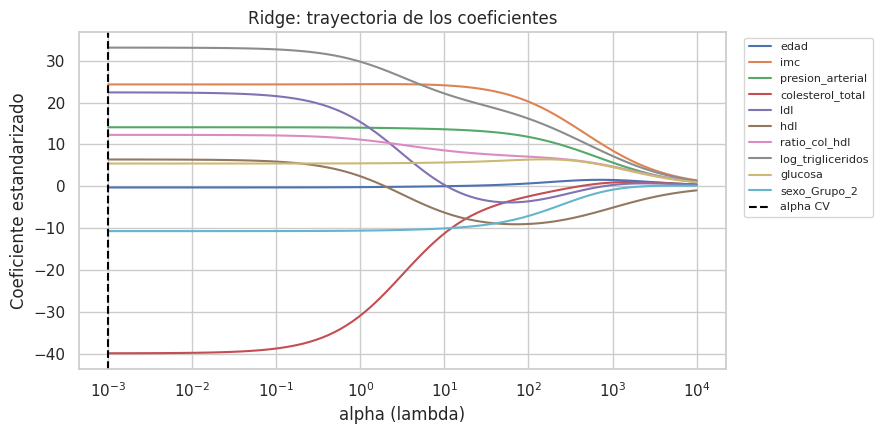

In [46]:
escalador_tmp = StandardScaler().fit(X_train)
X_train_std = escalador_tmp.transform(X_train)
trayectoria_ridge = np.array([Ridge(alpha=a).fit(X_train_std, y_train).coef_ for a in malla_alphas_ridge])

fig, ax = plt.subplots(figsize=(9, 4.5))
for j, nombre in enumerate(X_train.columns):
    ax.plot(malla_alphas_ridge, trayectoria_ridge[:, j], label=nombre)
ax.axvline(alpha_ridge, color="black", ls="--", label="alpha CV")
ax.set_xscale("log"); ax.set_xlabel("alpha (lambda)"); ax.set_ylabel("Coeficiente estandarizado")
ax.set_title("Ridge: trayectoria de los coeficientes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 12.2 Lasso (penalización L1)

$$
\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{p}|\beta_j|
\right]
$$

- **Reduce los coeficientes**, y por la forma de la penalización **algunos llegan exactamente a cero**.
- Por ello puede funcionar como **selección automática de variables**.
- Con predictores muy correlacionados, tiende a quedarse con uno y descartar los demás de forma algo arbitraria: el conjunto elegido puede ser inestable.

> Nota técnica: en scikit-learn la suma de cuadrados de Lasso se multiplica por $\frac{1}{2n}$; esto sólo cambia la escala numérica de $\lambda$, no la lógica del método.

`LassoCV` genera automáticamente una malla de 100 valores de $\lambda$ y elige el que minimiza el error cuadrático medio de validación cruzada.

In [47]:
pipe_lasso = crear_pipeline(LassoCV(cv=kf, max_iter=50000, random_state=RANDOM_STATE))
pipe_lasso.fit(X_train, y_train)

lasso = pipe_lasso.named_steps["modelo"]
print(f"Alpha (lambda) óptimo por validación cruzada: {lasso.alpha_:.4f}")

coef_lasso = pd.DataFrame({
    "coef_estandarizado": pd.Series(lasso.coef_, index=X_train.columns),
    "coef_escala_original": llevar_a_escala_original(pipe_lasso, X_train.columns).drop("const"),
})
display(coef_lasso)

seleccion_lasso_vars = coef_lasso.index[coef_lasso["coef_estandarizado"].abs() > 1e-10].tolist()
descartadas_lasso = [v for v in X_train.columns if v not in seleccion_lasso_vars]
print("Variables con coeficiente distinto de cero:", seleccion_lasso_vars)
print("Variables descartadas por Lasso (coef = 0):", descartadas_lasso if descartadas_lasso else "ninguna")

pred_lasso_test = pipe_lasso.predict(X_test)
print("Desempeño en PRUEBA (Lasso):", {k: round(v, 4) for k, v in metricas_regresion(y_test, pred_lasso_test).items()})

Alpha (lambda) óptimo por validación cruzada: 0.0440


,coef_estandarizado,coef_escala_original
edad,-0.1759,-0.0135
imc,24.3654,5.4557
presion_arterial,13.9743,1.0093
colesterol_total,-33.0365,-0.9409
ldl,17.1720,0.5599
hdl,3.1206,0.2348
ratio_col_hdl,11.0751,8.4233
log_trigliceridos,30.6729,58.3439
glucosa,5.4024,0.4586
sexo_Grupo_2,-10.6151,-21.2611


Variables con coeficiente distinto de cero: ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Variables descartadas por Lasso (coef = 0): ninguna
Desempeño en PRUEBA (Lasso): {'R2': 0.5677, 'MAE': 42.868, 'MSE': 2723.7512, 'RMSE': 52.1896}


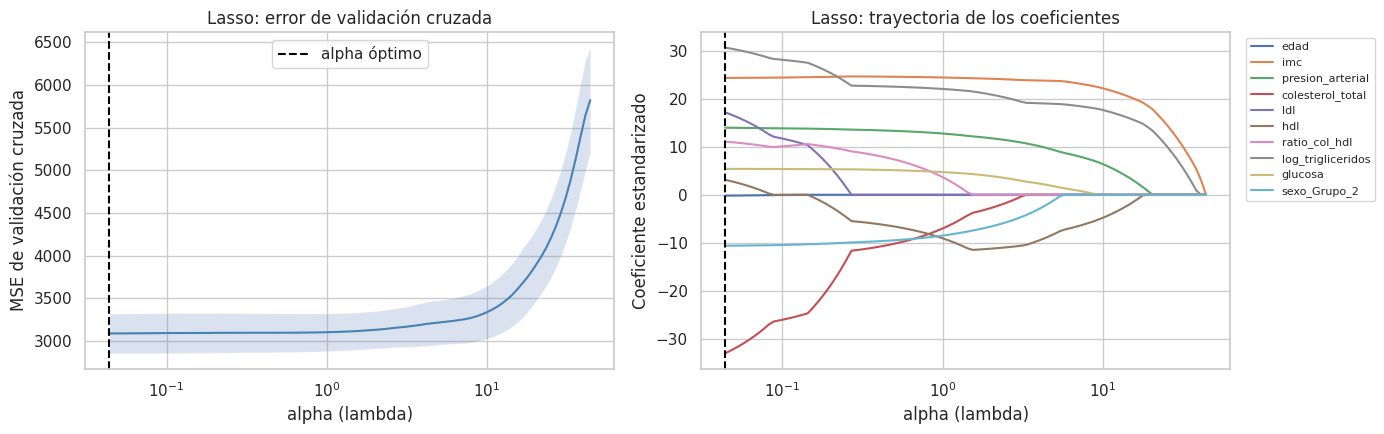

In [48]:
# Curva de validación cruzada y trayectoria de coeficientes de Lasso
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

mse_medio = lasso.mse_path_.mean(axis=1)
mse_de = lasso.mse_path_.std(axis=1)
ejes[0].plot(lasso.alphas_, mse_medio, color="steelblue")
ejes[0].fill_between(lasso.alphas_, mse_medio - mse_de, mse_medio + mse_de, alpha=0.2)
ejes[0].axvline(lasso.alpha_, color="black", ls="--", label="alpha óptimo")
ejes[0].set_xscale("log"); ejes[0].set_xlabel("alpha (lambda)"); ejes[0].set_ylabel("MSE de validación cruzada")
ejes[0].set_title("Lasso: error de validación cruzada"); ejes[0].legend()

trayectoria_lasso = np.array([Lasso(alpha=a, max_iter=50000).fit(X_train_std, y_train).coef_
                              for a in lasso.alphas_])
for j, nombre in enumerate(X_train.columns):
    ejes[1].plot(lasso.alphas_, trayectoria_lasso[:, j], label=nombre)
ejes[1].axvline(lasso.alpha_, color="black", ls="--")
ejes[1].set_xscale("log"); ejes[1].set_xlabel("alpha (lambda)"); ejes[1].set_ylabel("Coeficiente estandarizado")
ejes[1].set_title("Lasso: trayectoria de los coeficientes")
ejes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Complemento: regla de "un error estándar"

Cuando la curva de error de validación cruzada es muy plana, muchos valores de $\lambda$ predicen prácticamente igual. La **regla de 1 error estándar** elige el $\lambda$ **más grande** (modelo más simple) cuyo error está a no más de un error estándar del mínimo. Es un criterio de parsimonia muy usado.

In [49]:
mse_min = mse_medio.min()
error_est = lasso.mse_path_.std(axis=1)[np.argmin(mse_medio)] / np.sqrt(lasso.mse_path_.shape[1])
alpha_1se = lasso.alphas_[mse_medio <= mse_min + error_est].max()
lasso_1se = Lasso(alpha=alpha_1se, max_iter=50000).fit(X_train_std, y_train)
vars_1se = X_train.columns[np.abs(lasso_1se.coef_) > 1e-10].tolist()
print(f"alpha mínimo CV = {lasso.alpha_:.4f} | alpha regla 1-EE = {alpha_1se:.4f}")
print(f"Variables retenidas con la regla 1-EE ({len(vars_1se)}): {vars_1se}")
print(f"Variables descartadas con la regla 1-EE: {[v for v in X_train.columns if v not in vars_1se]}")

alpha mínimo CV = 0.0440 | alpha regla 1-EE = 3.8299
Variables retenidas con la regla 1-EE (6): ['imc', 'presion_arterial', 'hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Variables descartadas con la regla 1-EE: ['edad', 'colesterol_total', 'ldl', 'ratio_col_hdl']


**Interpretación:** a medida que $\lambda$ crece (hacia la derecha), más coeficientes se vuelven cero. Las variables que "sobreviven" hasta valores altos de $\lambda$ son las que más aportan a la predicción. Las variables seleccionadas por Lasso pueden reajustarse después con OLS (**OLS post-Lasso**) para obtener coeficientes sin encogimiento e inferencia tradicional (con la advertencia de que los p-valores tras una selección son optimistas).

## 12.3 Elastic Net (opcional)

Combina ambas penalizaciones:

$$
\min_{\beta}\left[\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2 + \lambda\left(\rho\sum_j|\beta_j| + \frac{1-\rho}{2}\sum_j\beta_j^2\right)\right]
$$

donde $\rho$ (`l1_ratio`) regula la mezcla: $\rho=1$ es Lasso y $\rho\to0$ se acerca a Ridge. Es útil cuando hay grupos de predictores correlacionados. Aquí se incluye como **contenido complementario**, no como modelo principal.

In [50]:
pipe_enet = crear_pipeline(ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0], cv=kf,
                                        max_iter=50000, random_state=RANDOM_STATE))
pipe_enet.fit(X_train, y_train)
enet = pipe_enet.named_steps["modelo"]
print(f"Elastic Net -> alpha óptimo: {enet.alpha_:.4f} | l1_ratio óptimo: {enet.l1_ratio_}")
coef_enet = pd.Series(enet.coef_, index=X_train.columns, name="coef_estandarizado")
display(coef_enet.to_frame())
seleccion_enet_vars = coef_enet.index[coef_enet.abs() > 1e-10].tolist()
pred_enet_test = pipe_enet.predict(X_test)

Elastic Net -> alpha óptimo: 0.0440 | l1_ratio óptimo: 1.0


,coef_estandarizado
edad,-0.1759
imc,24.3654
presion_arterial,13.9743
colesterol_total,-33.0365
ldl,17.1720
hdl,3.1206
ratio_col_hdl,11.0751
log_trigliceridos,30.6729
glucosa,5.4024
sexo_Grupo_2,-10.6151


## 📝 Para el informe

Reporte, para Ridge y Lasso: el valor de $\lambda$ elegido por validación cruzada, la tabla de coeficientes, las variables descartadas por Lasso y una interpretación de lo que aportan frente al OLS (estabilidad ante colinealidad, selección, capacidad predictiva).

---
# PARTE 13. Comparación de estrategias de selección

**¿Qué se hace?** Se comparan todos los enfoques en una misma tabla.

- **R² ajustado, AIC, BIC:** sólo aplican a los modelos OLS (se basan en la verosimilitud del modelo sin penalización).
- **RMSE CV (entrenamiento):** error de validación cruzada de 5 particiones, calculado **sólo con entrenamiento**. Es el criterio **adecuado para comparar y decidir**.
- **RMSE test:** error en el conjunto de prueba. Se reporta como **verificación final**, no para elegir.

Para Ridge, Lasso y Elastic Net, el RMSE CV se obtiene con **validación cruzada anidada**: en cada *fold* externo se vuelve a elegir $\lambda$ con un CV interno, de modo que la estimación no es optimista.

In [51]:
def fila_ols(nombre, variables):
    m = ajustar_ols(X_train, y_train, variables)
    pred_test = m.predict(con_constante(X_test[variables]))
    return {"Método": nombre, "n_variables": len(variables), "Variables seleccionadas": ", ".join(variables),
            "R2_ajustado": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic,
            "RMSE_CV_train": rmse_cv(X_train, y_train, variables).mean(),
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test))}


def fila_regularizado(nombre, pipeline, variables_texto, n_vars):
    cv_rmse = -cross_val_score(pipeline, X_train, y_train, cv=kf,
                               scoring="neg_root_mean_squared_error").mean()
    return {"Método": nombre, "n_variables": n_vars, "Variables seleccionadas": variables_texto,
            "R2_ajustado": np.nan, "AIC": np.nan, "BIC": np.nan,
            "RMSE_CV_train": cv_rmse,
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pipeline.predict(X_test)))}


filas = [fila_ols(nombre, vars_) for nombre, vars_ in candidatos_ols.items()]
if seleccion_lasso_vars:
    filas.append(fila_ols("OLS post-Lasso", seleccion_lasso_vars))
if vars_1se:
    filas.append(fila_ols("OLS post-Lasso (regla 1-EE)", vars_1se))
filas.append(fila_regularizado("Lasso", pipe_lasso, ", ".join(seleccion_lasso_vars), len(seleccion_lasso_vars)))
filas.append(fila_regularizado("Ridge", pipe_ridge, "Todas", X_train.shape[1]))
filas.append(fila_regularizado("Elastic Net (opcional)", pipe_enet, ", ".join(seleccion_enet_vars), len(seleccion_enet_vars)))

tabla_comparacion = pd.DataFrame(filas).set_index("Método")
display(tabla_comparacion.style
        .format({"R2_ajustado": "{:.4f}", "AIC": "{:.2f}", "BIC": "{:.2f}",
                 "RMSE_CV_train": "{:.3f}", "RMSE_test": "{:.3f}"}, na_rep="NA")
        .highlight_min(subset=["RMSE_CV_train"], color="#d4edda"))

,n_variables,Variables seleccionadas,R2_ajustado,AIC,BIC,RMSE_CV_train,RMSE_test
Método,,,,,,,
Completo,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4870,3839.14,3881.68,55.524,52.194
Backward (p-valor),6,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, sexo_Grupo_2",0.4865,3835.54,3862.61,55.163,51.868
Forward (p-valor),5,"imc, log_trigliceridos, presion_arterial, hdl, sexo_Grupo_2",0.4815,3838.00,3861.20,55.342,51.689
Stepwise (p-valor),5,"imc, log_trigliceridos, presion_arterial, hdl, sexo_Grupo_2",0.4815,3838.00,3861.20,55.342,51.689
Backward (AIC),7,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4886,3835.08,3866.01,55.585,52.501
Backward (BIC),6,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, sexo_Grupo_2",0.4865,3835.54,3862.61,55.163,51.868
OLS post-Lasso,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4870,3839.14,3881.68,55.524,52.194
OLS post-Lasso (regla 1-EE),6,"imc, presion_arterial, hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4827,3838.19,3865.26,55.760,52.202
Lasso,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",NA,NA,NA,55.754,52.190


**Cómo leer la tabla:**

- No todas las métricas aplican igual a todos los enfoques (por eso aparecen **NA**).
- **Ridge y Lasso se comparan especialmente por capacidad predictiva** (RMSE CV y RMSE test).
- **OLS permite además inferencia estadística tradicional** (p-valores, intervalos de confianza, pruebas de supuestos).
- Diferencias pequeñas de RMSE entre modelos (por ejemplo, menores que la variabilidad entre *folds*, Parte 19) no son concluyentes: en ese caso, prefiera el modelo **más simple e interpretable**.

## ❓ Preguntas para el estudiante

1. ¿Qué modelo tiene menor RMSE de validación cruzada? ¿La diferencia con los demás es relevante?
2. ¿Los modelos reducidos predicen peor que el completo? Si predicen igual con menos variables, ¿qué indica?
3. ¿Qué variables aparecen en casi todos los métodos? (Son candidatas robustas.)
4. ¿Ridge o Lasso mejoran de forma importante al OLS? ¿Qué sugiere esto sobre la multicolinealidad o el sobreajuste?

---
# PARTE 14. Selección del modelo final

La elección del modelo final **no es automática**. Considere simultáneamente:

| Criterio | Pregunta |
|---|---|
| Fundamento conceptual | ¿Las variables tienen sentido y los signos son plausibles? |
| Parsimonia | ¿Hay un modelo más simple con desempeño similar? |
| Multicolinealidad | ¿Los VIF son aceptables? |
| Ajuste | ¿Cómo son el $R^2$ ajustado, AIC y BIC? |
| Supuestos | ¿Los residuos cumplen razonablemente los supuestos? (Parte 15) |
| Estabilidad | ¿Las variables aparecen en varios métodos de selección? |
| Capacidad predictiva | ¿Cómo es el RMSE de validación cruzada? |
| Interpretabilidad | ¿Se puede explicar a un público no técnico? |

**Recomendaciones:**

- El modelo que se reporte como **ecuación** debe ser preferiblemente un **OLS bien especificado**.
- **Lasso** puede usarse como apoyo para identificar variables potencialmente útiles.
- **Ridge** puede usarse como comparación cuando exista multicolinealidad o interés predictivo.

## Definición del modelo final ✏️ EDITAR (decisión del estudiante)

In [52]:
# ===============================================================
# ✏️ EDITAR: DECISIÓN DEL ESTUDIANTE
# Reemplace la lista por las variables del modelo que usted JUSTIFIQUE en el informe.
# Por defecto se toma el resultado de Stepwise sólo para que el cuadernillo pueda
# ejecutarse completo; esto NO significa que sea el mejor modelo para sus datos.
# Opciones: list(X_train.columns), seleccion_backward_vars, seleccion_forward_vars,
#           seleccion_stepwise_vars, seleccion_aic_vars, seleccion_lasso_vars, o una lista manual.
# ===============================================================
predictores_finales = list(seleccion_stepwise_vars)

assert len(predictores_finales) > 0, "El modelo final debe tener al menos un predictor."
print("Predictores del modelo final:", predictores_finales)

modelo_final = ajustar_ols(X_train, y_train, predictores_finales)
modelo_final.summary()

Predictores del modelo final: ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             progresion   R-squared:                       0.489
Model:                            OLS   Adj. R-squared:                  0.482
Method:                 Least Squares   F-statistic:                     66.38
Date:                Fri, 25 Sep 2026   Prob (F-statistic):           1.60e-48
Time:                        16:58:30   Log-Likelihood:                -1913.0
No. Observations:                 353   AIC:                             3838.
Df Residuals:                     347   BIC:                             3861.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -212.7210     39.006     -5.454      0.000    -289.438    -136.004
imc                   5.5739      0.782      7.131      0.000       4.037       7.111
log_trigliceridos    39.8917      6.650      5.999      0.000      26.812      52.971
presion_arterial      1.0466      0.240      4.369      0.000       0.575       1.518
hdl                  -1.1399      0.270     -4.224      0.000      -1.671      -0.609
sexo_Grupo_2        -20.1158      6.556     -3.068      0.002     -33.011      -7.221
==============================================================================
Omnibus:                        1.424   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.491   Jarque-Bera (JB):                1.325
Skew:                           0.014   Prob(JB):                        0.516
Kurtosis:                       2.701   Cond. No.                     1.48e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.48e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [53]:
display(Markdown("### Coeficientes del modelo final"))
tabla_coef_final = tabla_coeficientes(modelo_final)
display(tabla_coef_final)
display(resumen_global(modelo_final).to_frame("modelo final"))

display(Markdown("### Ecuación estimada del modelo final"))
ec_final_texto, ec_final_latex = ecuacion_modelo(modelo_final.params, variable_objetivo, decimales=3)
print(ec_final_texto)
display(Math(ec_final_latex))

display(Markdown("### Interpretación (borrador a revisar)"))
display(Markdown(interpretar_coeficientes(modelo_final, variable_objetivo, columnas_dummy)))

display(Markdown("### VIF del modelo final"))
tabla_vif_final = calcular_vif(X_train[predictores_finales]) if len(predictores_finales) > 1 else \
    pd.DataFrame({"Variable": predictores_finales, "VIF": [1.0], "lectura": ["un solo predictor"]})
display(tabla_vif_final)

### Coeficientes del modelo final

,coeficiente,error_estandar,t,p_valor,IC_95%_inf,IC_95%_sup,significativo
const,-212.7210,39.0057,-5.4536,0.0000,-289.4384,-136.0037,sí
imc,5.5739,0.7817,7.1310,0.0000,4.0366,7.1113,sí
log_trigliceridos,39.8917,6.6502,5.9986,0.0000,26.8119,52.9714,sí
presion_arterial,1.0466,0.2395,4.3689,0.0000,0.5754,1.5177,sí
hdl,-1.1399,0.2699,-4.2238,0.0000,-1.6707,-0.6091,sí
sexo_Grupo_2,-20.1158,6.5564,-3.0681,0.0023,-33.0110,-7.2205,sí


,modelo final
n,353.0000
p (predictores),5.0000
R2,0.4889
R2_ajustado,0.4815
F,66.3839
p_valor_F,0.0000
AIC,"3,837.9964"
BIC,"3,861.1952"
sigma_residual,55.0858


### Ecuación estimada del modelo final

progresion_estimado = -212.721 + 5.574*imc + 39.892*log_trigliceridos + 1.047*presion_arterial - 1.140*hdl - 20.116*sexo_Grupo_2


<IPython.core.display.Math object>

### Interpretación (borrador a revisar)

- **Intercepto:** valor esperado de progresion cuando todos los predictores valen 0: -212.7210. Evalúe si ese escenario tiene sentido.
- **imc:** controlando por las demás variables del modelo, un incremento de una unidad en imc se asocia con una aumento promedio de 5.5739 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **log_trigliceridos:** controlando por las demás variables del modelo, un incremento de una unidad en log_trigliceridos se asocia con una aumento promedio de 39.8917 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **presion_arterial:** controlando por las demás variables del modelo, un incremento de una unidad en presion_arterial se asocia con una aumento promedio de 1.0466 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **hdl:** controlando por las demás variables del modelo, un incremento de una unidad en hdl se asocia con una disminución promedio de 1.1399 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **sexo_Grupo_2:** controlando por las demás variables, esta categoría presenta en promedio un valor de progresion 20.1158 unidades menor que la categoría de referencia; estadísticamente significativo (p = 0.0023).

### VIF del modelo final

,Variable,VIF,lectura
0,hdl,1.4969,baja/moderada
1,log_trigliceridos,1.4219,baja/moderada
2,imc,1.4176,baja/moderada
3,presion_arterial,1.2797,baja/moderada
4,sexo_Grupo_2,1.2465,baja/moderada


## 📝 Para el informe: selección de variables y modelo construido

- Describa los métodos de selección aplicados y presente la tabla comparativa.
- Justifique la elección del modelo final con **varios** criterios (conceptual, parsimonia, VIF, AIC/BIC, RMSE CV).
- Presente la ecuación estimada y la tabla de coeficientes con p-valores e IC 95%.
- Interprete los coeficientes en las unidades de las variables y sin lenguaje causal.

---
# PARTE 15. Validación de supuestos

**¿Qué se hace?** Se analizan los **residuos** $e_i = y_i - \hat y_i$ del modelo final (en entrenamiento) para verificar los supuestos del modelo lineal.

**¿Por qué?** Los p-valores, intervalos de confianza e intervalos de predicción de OLS **sólo son confiables si los supuestos se cumplen razonablemente**. Las predicciones puntuales pueden seguir siendo útiles aun con violaciones leves, pero la inferencia no.

| Supuesto | Qué se verifica | Herramienta |
|---|---|---|
| Linealidad | La relación entre $Y$ y los $X$ es lineal | Residuos vs ajustados, residuos vs cada predictor, prueba Rainbow |
| Normalidad | Los errores siguen una distribución normal | Histograma, Q-Q plot, Shapiro-Wilk, Jarque-Bera |
| Homocedasticidad | Varianza de los errores constante | Residuos vs ajustados, escala-localización, Breusch-Pagan |
| Independencia | Errores no correlacionados entre sí | Durbin-Watson |
| Sin influencia excesiva | Ninguna observación domina el ajuste | Residuos estudentizados, leverage, distancia de Cook |

In [54]:
residuos = modelo_final.resid
ajustados = modelo_final.fittedvalues
influencia = modelo_final.get_influence()
residuos_estud = influencia.resid_studentized_external
n_train, p_final = int(modelo_final.nobs), int(modelo_final.df_model)
print(f"n = {n_train}, p = {p_final}, media de residuos = {residuos.mean():.2e} (debe ser ≈ 0)")

n = 353, p = 5, media de residuos = -2.21e-13 (debe ser ≈ 0)


## 15.1 Linealidad

**Gráfico de residuos vs valores ajustados.** Si el modelo es adecuado, los puntos deben distribuirse **aleatoriamente alrededor de cero**, sin curvas ni patrones. La línea LOWESS (roja) debería ser aproximadamente horizontal.

- Un patrón en forma de **U** o curva sugiere **no linealidad** (falta un término cuadrático, una transformación o una variable).
- Se complementa con residuos frente a cada predictor numérico y con la **prueba Rainbow** ($H_0$: la relación es lineal).

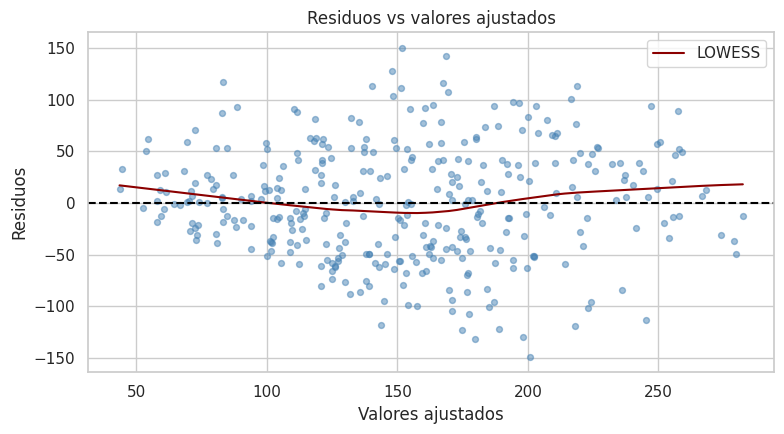

Prueba Rainbow de linealidad: estadístico = 1.2223, p-valor = 0.0939


In [55]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(ajustados, residuos, alpha=0.5, s=18, color="steelblue")
suav = sm.nonparametric.lowess(residuos, ajustados, frac=0.6)
ax.plot(suav[:, 0], suav[:, 1], color="darkred", label="LOWESS")
ax.axhline(0, color="black", ls="--")
ax.set_xlabel("Valores ajustados"); ax.set_ylabel("Residuos")
ax.set_title("Residuos vs valores ajustados"); ax.legend()
plt.tight_layout(); plt.show()

rainbow_est, rainbow_p = linear_rainbow(modelo_final)
print(f"Prueba Rainbow de linealidad: estadístico = {rainbow_est:.4f}, p-valor = {rainbow_p:.4f}")

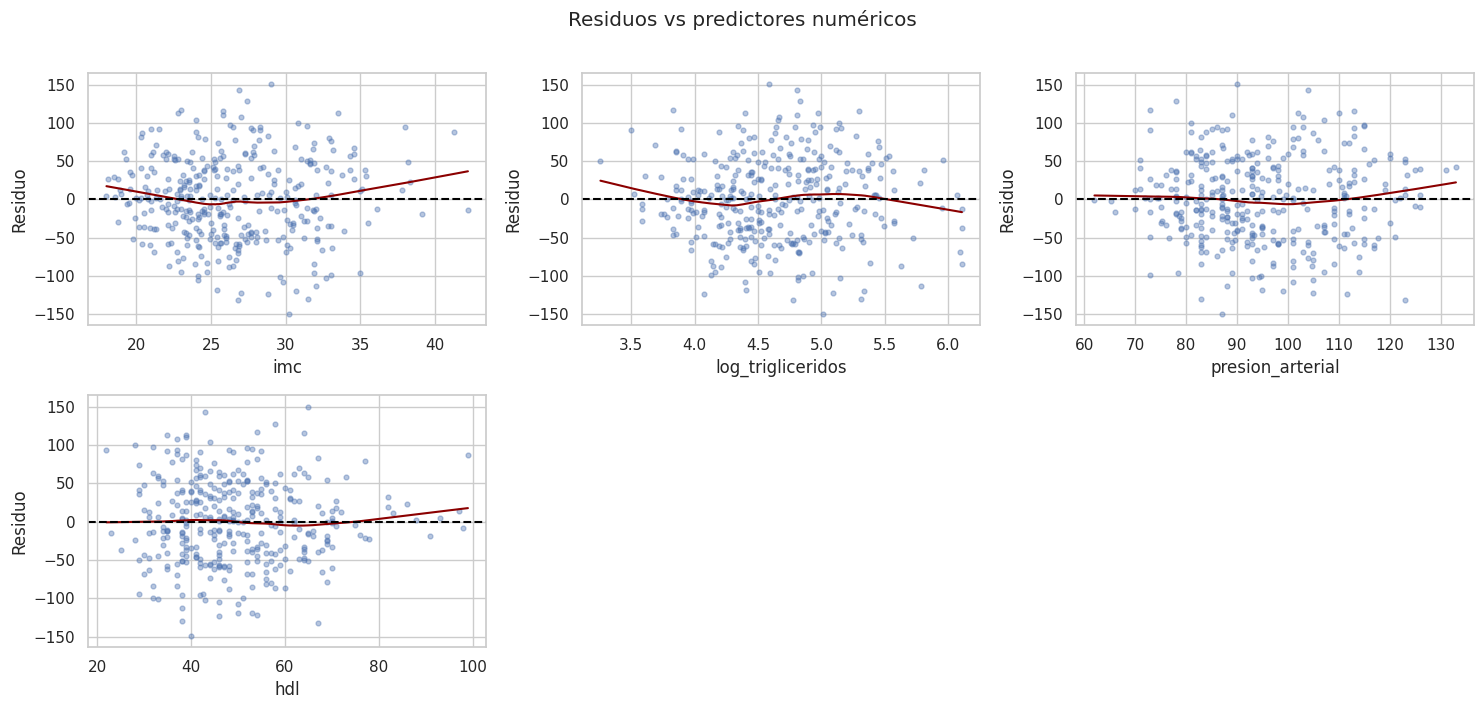

In [56]:
# Residuos frente a cada predictor numérico del modelo final
num_finales = [v for v in predictores_finales if v in pred_numericos]
if num_finales:
    n_col = 3
    n_fil = int(np.ceil(len(num_finales) / n_col))
    fig, ejes = plt.subplots(n_fil, n_col, figsize=(5 * n_col, 3.5 * n_fil), squeeze=False)
    for ax, var in zip(ejes.flat, num_finales):
        ax.scatter(X_train[var], residuos, alpha=0.4, s=12)
        s_ = sm.nonparametric.lowess(residuos, X_train[var], frac=0.6)
        ax.plot(s_[:, 0], s_[:, 1], color="darkred")
        ax.axhline(0, color="black", ls="--"); ax.set_xlabel(var); ax.set_ylabel("Residuo")
    for ax in list(ejes.flat)[len(num_finales):]:
        ax.set_visible(False)
    fig.suptitle("Residuos vs predictores numéricos", y=1.01)
    plt.tight_layout(); plt.show()

## 15.2 Normalidad de los residuos

- **Histograma + KDE:** debería parecerse a una campana simétrica centrada en 0.
- **Q-Q plot:** los puntos deberían seguir la diagonal; desviaciones en los extremos indican colas pesadas o asimetría.
- **Shapiro-Wilk** y **Jarque-Bera:** $H_0$: los residuos son normales. Un p-valor $< \alpha$ indica evidencia contra la normalidad.

> ⚠️ **Limitaciones:** con muestras **grandes**, las pruebas detectan desviaciones mínimas sin importancia práctica; con muestras **pequeñas**, tienen poca potencia. Por eso deben leerse **junto con los gráficos**. Además, gracias al teorema central del límite, la inferencia sobre los coeficientes es bastante robusta a no normalidad moderada cuando $n$ es grande. Shapiro-Wilk se recomienda para $n \le 5000$.

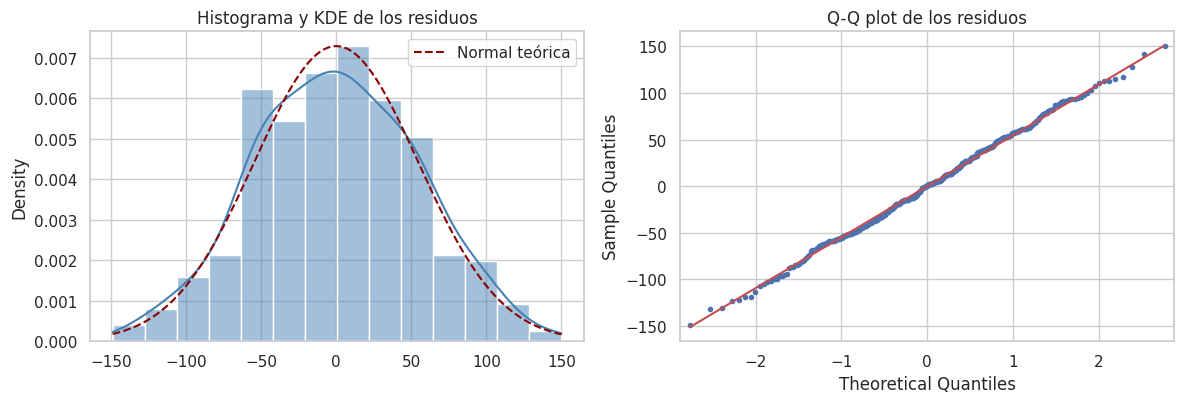

Shapiro-Wilk: W = 0.9971, p-valor = 0.7977
Jarque-Bera: JB = 1.3248, p-valor = 0.5156 | asimetría = 0.014, curtosis = 2.701


In [57]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(residuos, kde=True, ax=ejes[0], color="steelblue", stat="density")
x_ = np.linspace(residuos.min(), residuos.max(), 200)
ejes[0].plot(x_, stats.norm.pdf(x_, residuos.mean(), residuos.std()), color="darkred", ls="--", label="Normal teórica")
ejes[0].set_title("Histograma y KDE de los residuos"); ejes[0].legend()
sm.qqplot(residuos, line="s", ax=ejes[1], markersize=3)
ejes[1].set_title("Q-Q plot de los residuos")
plt.tight_layout(); plt.show()

if len(residuos) <= 5000:
    sw_est, sw_p = stats.shapiro(residuos)
    print(f"Shapiro-Wilk: W = {sw_est:.4f}, p-valor = {sw_p:.4f}")
else:
    sw_est, sw_p = np.nan, np.nan
    print("Shapiro-Wilk no se aplica (n > 5000); use Jarque-Bera y los gráficos.")
jb_est, jb_p, jb_asim, jb_curt = jarque_bera(residuos)
print(f"Jarque-Bera: JB = {jb_est:.4f}, p-valor = {jb_p:.4f} | asimetría = {jb_asim:.3f}, curtosis = {jb_curt:.3f}")

## 15.3 Homocedasticidad

Se espera que la dispersión de los residuos sea **constante** a lo largo de los valores ajustados. Un patrón de **embudo** (dispersión que crece o decrece) indica **heterocedasticidad**.

**Prueba de Breusch-Pagan:**

$$
H_0: \text{varianza constante (homocedasticidad)} \qquad H_1: \text{la varianza depende de los predictores}
$$

Si $p < \alpha$ hay evidencia de heterocedasticidad. Consecuencia: los coeficientes siguen siendo insesgados, pero los **errores estándar** (y por tanto p-valores e IC) no son confiables. Alternativas: transformar $Y$, usar errores estándar robustos (`fit(cov_type="HC3")`) o mínimos cuadrados ponderados.

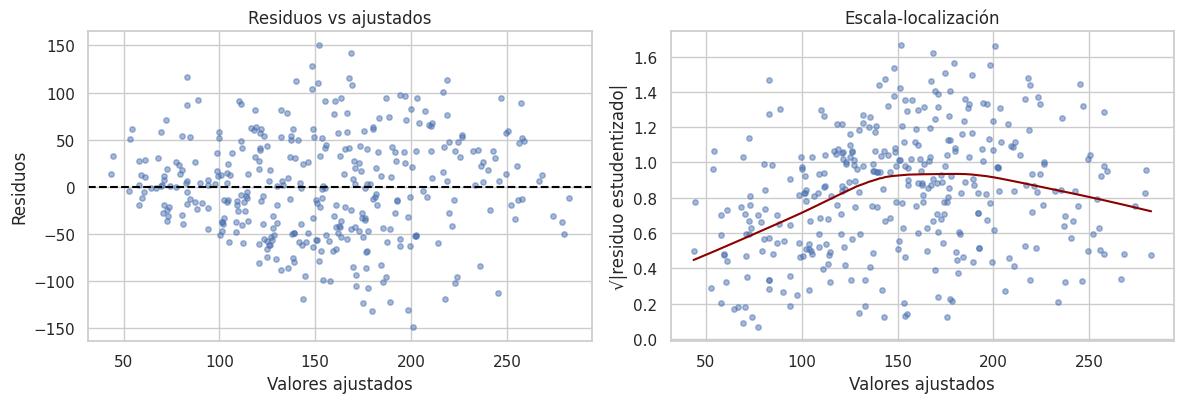

Breusch-Pagan: LM = 15.8767, p-valor = 0.0072 | F = 3.2684, p-valor = 0.0067


In [58]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ejes[0].scatter(ajustados, residuos, alpha=0.5, s=15)
ejes[0].axhline(0, color="black", ls="--")
ejes[0].set_xlabel("Valores ajustados"); ejes[0].set_ylabel("Residuos"); ejes[0].set_title("Residuos vs ajustados")

raiz_abs = np.sqrt(np.abs(residuos_estud))
ejes[1].scatter(ajustados, raiz_abs, alpha=0.5, s=15)
s_ = sm.nonparametric.lowess(raiz_abs, ajustados, frac=0.6)
ejes[1].plot(s_[:, 0], s_[:, 1], color="darkred")
ejes[1].set_xlabel("Valores ajustados"); ejes[1].set_ylabel("√|residuo estudentizado|")
ejes[1].set_title("Escala-localización")
plt.tight_layout(); plt.show()

bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residuos, modelo_final.model.exog)
print(f"Breusch-Pagan: LM = {bp_lm:.4f}, p-valor = {bp_lm_p:.4f} | F = {bp_f:.4f}, p-valor = {bp_f_p:.4f}")

In [59]:
# Complemento: comparación con errores estándar robustos a heterocedasticidad (HC3)
modelo_final_hc3 = sm.OLS(y_train, con_constante(X_train[predictores_finales])).fit(cov_type="HC3")
display(pd.DataFrame({
    "coef": modelo_final.params, "SE_clasico": modelo_final.bse, "p_clasico": modelo_final.pvalues,
    "SE_robusto_HC3": modelo_final_hc3.bse, "p_robusto_HC3": modelo_final_hc3.pvalues,
}))

,coef,SE_clasico,p_clasico,SE_robusto_HC3,p_robusto_HC3
const,-212.7210,39.0057,0.0000,36.5265,0.0000
imc,5.5739,0.7817,0.0000,0.8187,0.0000
log_trigliceridos,39.8917,6.6502,0.0000,6.8433,0.0000
presion_arterial,1.0466,0.2395,0.0000,0.2489,0.0000
hdl,-1.1399,0.2699,0.0000,0.2539,0.0000
sexo_Grupo_2,-20.1158,6.5564,0.0023,6.4598,0.0018


**Interpretación:** si las conclusiones de significancia no cambian al usar errores robustos, la heterocedasticidad (si existe) no altera la inferencia de manera importante.

## 15.4 Independencia

El estadístico de **Durbin-Watson** evalúa autocorrelación de primer orden en los residuos:

- $DW \approx 2$: sin autocorrelación.
- $DW < 1.5$: posible autocorrelación positiva; $DW > 2.5$: posible autocorrelación negativa (umbrales orientativos).

> Es especialmente relevante cuando los datos tienen **estructura temporal u ordenada** (series de tiempo, mediciones sucesivas, datos espaciales ordenados). En datos de corte transversal con orden arbitrario, su valor depende del orden de las filas y tiene menos sentido; la independencia se justifica principalmente por el **diseño de recolección**.

In [60]:
dw = durbin_watson(residuos)
print(f"Durbin-Watson: {dw:.4f}")

Durbin-Watson: 2.1761


## 15.5 Observaciones atípicas e influyentes

| Medida | Qué detecta | Umbral orientativo |
|---|---|---|
| Residuo estudentizado | Observación mal ajustada (atípica en $Y$) | $|r_i| > 3$ (o > 2 para revisar) |
| Leverage $h_{ii}$ | Valores extremos en los $X$ | $h_{ii} > 2(p+1)/n$ |
| Distancia de Cook $D_i$ | Cuánto cambian **todos** los coeficientes si se elimina la observación | $D_i > 4/n$ (revisar); $D_i > 1$ (muy influyente) |

> **No elimine observaciones automáticamente.** Revise si son errores de digitación o medición, casos de otra población o valores legítimos. Si decide excluir alguna, reporte el modelo **con y sin** ella y justifique.

In [61]:
distancia_cook = influencia.cooks_distance[0]
leverage = influencia.hat_matrix_diag
umbral_cook = 4 / n_train
umbral_lev = 2 * (p_final + 1) / n_train

tabla_influencia = pd.DataFrame({
    "residuo_estudentizado": residuos_estud, "leverage": leverage, "cook": distancia_cook,
}, index=X_train.index)
tabla_influencia["atipico_|r|>3"] = tabla_influencia["residuo_estudentizado"].abs() > 3
tabla_influencia["alto_leverage"] = tabla_influencia["leverage"] > umbral_lev
tabla_influencia["cook>4/n"] = tabla_influencia["cook"] > umbral_cook

print(f"Umbrales -> Cook: 4/n = {umbral_cook:.4f} | leverage: 2(p+1)/n = {umbral_lev:.4f}")
print(f"Atípicos (|r|>3): {tabla_influencia['atipico_|r|>3'].sum()} | "
      f"Alto leverage: {tabla_influencia['alto_leverage'].sum()} | "
      f"Cook > 4/n: {tabla_influencia['cook>4/n'].sum()} | Cook > 1: {(distancia_cook > 1).sum()}")

display(Markdown("**Las 10 observaciones con mayor distancia de Cook** (índice = fila original de la base):"))
display(tabla_influencia.sort_values("cook", ascending=False).head(10))

Umbrales -> Cook: 4/n = 0.0113 | leverage: 2(p+1)/n = 0.0340
Atípicos (|r|>3): 0 | Alto leverage: 21 | Cook > 4/n: 22 | Cook > 1: 0


**Las 10 observaciones con mayor distancia de Cook** (índice = fila original de la base):

,residuo_estudentizado,leverage,cook,atipico_|r|>3,alto_leverage,cook>4/n
256,1.6557,0.0536,0.0257,False,True,True
58,1.6295,0.0542,0.0252,False,True,True
92,-2.4377,0.0250,0.0250,False,False,True
29,2.1362,0.0256,0.0198,False,False,True
382,-2.0921,0.0266,0.0197,False,False,True
380,-2.2701,0.0225,0.0195,False,False,True
289,-2.4047,0.0200,0.0194,False,False,True
169,-1.5639,0.0450,0.0191,False,True,True
32,1.7422,0.0342,0.0178,False,True,True
417,-1.8328,0.0296,0.0170,False,False,True


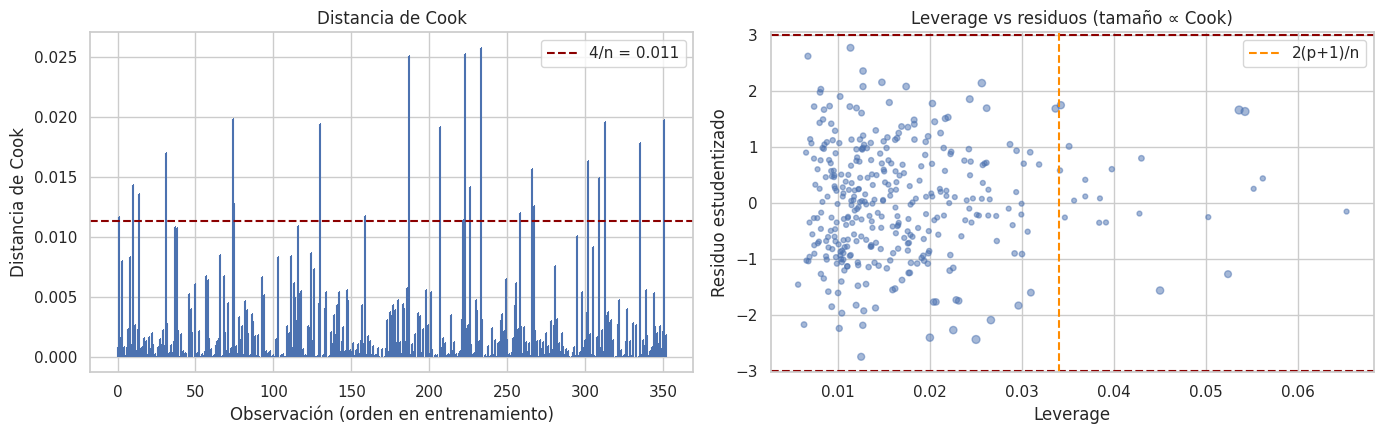

In [62]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].stem(np.arange(len(distancia_cook)), distancia_cook, markerfmt=",", basefmt=" ")
ejes[0].axhline(umbral_cook, color="darkred", ls="--", label=f"4/n = {umbral_cook:.3f}")
ejes[0].set_xlabel("Observación (orden en entrenamiento)"); ejes[0].set_ylabel("Distancia de Cook")
ejes[0].set_title("Distancia de Cook"); ejes[0].legend()

ejes[1].scatter(leverage, residuos_estud, s=12 + 800 * distancia_cook, alpha=0.5)
ejes[1].axhline(3, color="darkred", ls="--"); ejes[1].axhline(-3, color="darkred", ls="--")
ejes[1].axvline(umbral_lev, color="darkorange", ls="--", label="2(p+1)/n")
ejes[1].set_xlabel("Leverage"); ejes[1].set_ylabel("Residuo estudentizado")
ejes[1].set_title("Leverage vs residuos (tamaño ∝ Cook)"); ejes[1].legend()
plt.tight_layout(); plt.show()

---
# PARTE 16. Tabla resumen de diagnóstico

La tabla se construye **automáticamente** con los resultados calculados. La columna *Interpretación* es **orientativa**: debe contrastarse con los gráficos y redactarse con criterio propio.

In [63]:
def tabla_diagnostico(alpha=ALPHA):
    def lectura_p(p, ok, mal):
        return ok if p >= alpha else mal
    vif_max = tabla_vif_final["VIF"].max()
    filas = [
        {"Diagnóstico": "Linealidad", "Herramienta": "Residuos vs ajustados + Rainbow",
         "Resultado": f"p Rainbow = {rainbow_p:.4f}",
         "Interpretación": lectura_p(rainbow_p, "Sin evidencia de no linealidad (revise el gráfico)",
                                     "Posible no linealidad: revise transformaciones")},
        {"Diagnóstico": "Normalidad", "Herramienta": "Q-Q / Shapiro-Wilk / Jarque-Bera",
         "Resultado": f"p SW = {sw_p:.4f}; p JB = {jb_p:.4f}",
         "Interpretación": lectura_p(min(p for p in [sw_p, jb_p] if not np.isnan(p)),
                                     "Sin evidencia contra la normalidad",
                                     "Evidencia de no normalidad: valore su relevancia con el Q-Q plot y n")},
        {"Diagnóstico": "Homocedasticidad", "Herramienta": "Breusch-Pagan",
         "Resultado": f"LM = {bp_lm:.3f}; p = {bp_lm_p:.4f}",
         "Interpretación": lectura_p(bp_lm_p, "Sin evidencia de heterocedasticidad",
                                     "Evidencia de heterocedasticidad: considere errores robustos (HC3)")},
        {"Diagnóstico": "Independencia", "Herramienta": "Durbin-Watson",
         "Resultado": f"DW = {dw:.3f}",
         "Interpretación": "Sin autocorrelación de primer orden aparente" if 1.5 <= dw <= 2.5
                           else "Posible autocorrelación: revise el orden/diseño de los datos"},
        {"Diagnóstico": "Multicolinealidad", "Herramienta": "VIF",
         "Resultado": f"VIF máximo = {vif_max:.2f}",
         "Interpretación": "Colinealidad baja/moderada" if vif_max <= 5
                           else ("Revisar colinealidad (VIF > 5)" if vif_max <= 10 else "Posible problema importante (VIF > 10)")},
        {"Diagnóstico": "Influencia", "Herramienta": "Distancia de Cook",
         "Resultado": f"{int((distancia_cook > umbral_cook).sum())} obs. > 4/n; {int((distancia_cook > 1).sum())} obs. > 1",
         "Interpretación": "Ninguna observación extremadamente influyente (Cook < 1)" if (distancia_cook <= 1).all()
                           else "Hay observaciones muy influyentes: revisar"},
    ]
    return pd.DataFrame(filas)

tabla_diag = tabla_diagnostico()
display(tabla_diag)

,Diagnóstico,Herramienta,Resultado,Interpretación
0,Linealidad,Residuos vs ajustados + Rainbow,p Rainbow = 0.0939,Sin evidencia de no linealidad (revise el gráf...
1,Normalidad,Q-Q / Shapiro-Wilk / Jarque-Bera,p SW = 0.7977; p JB = 0.5156,Sin evidencia contra la normalidad
2,Homocedasticidad,Breusch-Pagan,LM = 15.877; p = 0.0072,Evidencia de heterocedasticidad: considere err...
3,Independencia,Durbin-Watson,DW = 2.176,Sin autocorrelación de primer orden aparente
4,Multicolinealidad,VIF,VIF máximo = 1.50,Colinealidad baja/moderada
5,Influencia,Distancia de Cook,22 obs. > 4/n; 0 obs. > 1,Ninguna observación extremadamente influyente ...


## 📝 Para el informe: validación del modelo

Incluya la tabla resumen, los gráficos de residuos vs ajustados, Q-Q plot y distancia de Cook, y una discusión de cada supuesto: ¿se cumple razonablemente? Si no, ¿qué consecuencias tiene y qué medida se tomó (transformación, errores robustos, revisión de observaciones)?

---
# PARTE 17. Evaluación del ajuste (entrenamiento)

**¿Qué se hace?** Se mide qué tan bien reproduce el modelo los datos con los que fue estimado.

| Métrica | Fórmula | Lectura |
|---|---|---|
| $R^2$ | $1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | Proporción de variabilidad de $Y$ explicada (0 a 1). |
| $R^2$ ajustado | $1-(1-R^2)\dfrac{n-1}{n-p-1}$ | Penaliza el número de predictores. |
| MAE | $\frac1n\sum|y_i-\hat y_i|$ | Error absoluto promedio, en unidades de $Y$. Robusto a atípicos. |
| MSE | $\frac1n\sum(y_i-\hat y_i)^2$ | Error cuadrático medio (unidades de $Y$ al cuadrado). |
| RMSE | $\sqrt{MSE}$ | Error típico en unidades de $Y$. Penaliza más los errores grandes. |

In [64]:
pred_train = modelo_final.predict(con_constante(X_train[predictores_finales]))
metricas_train = metricas_regresion(y_train, pred_train, p=len(predictores_finales))
display(pd.Series(metricas_train).to_frame("Entrenamiento"))
print(f"Como referencia, la desviación estándar de Y en entrenamiento es {y_train.std():.3f}; "
      f"el RMSE indica cuánto se reduce el error típico al usar el modelo en vez de la media.")

,Entrenamiento
R2,0.4889
R2_ajustado,0.4815
MAE,44.2333
MSE,"2,982.8650"
RMSE,54.6156


Como referencia, la desviación estándar de Y en entrenamiento es 76.503; el RMSE indica cuánto se reduce el error típico al usar el modelo en vez de la media.


---
# PARTE 18. Evaluación de la capacidad predictiva (prueba)

**¿Qué se hace?** Se aplica el modelo final, **sin reestimarlo**, al conjunto de prueba que no se usó en ninguna decisión.

**Cómo interpretar la comparación train vs test:**

- **Buen ajuste y buena generalización:** métricas similares en ambos conjuntos.
- **Posible sobreajuste:** error mucho menor en entrenamiento que en prueba (el modelo "memorizó" particularidades de la muestra).
- **Posible subajuste:** error alto en **ambos** conjuntos (faltan variables, relaciones no lineales o el fenómeno es muy ruidoso).

In [65]:
pred_test = modelo_final.predict(con_constante(X_test[predictores_finales]))
metricas_test = metricas_regresion(y_test, pred_test, p=len(predictores_finales))

tabla_train_test = pd.DataFrame({"Train": metricas_train, "Test": metricas_test}).loc[
    ["R2", "R2_ajustado", "MAE", "MSE", "RMSE"]]
tabla_train_test["Diferencia (Test - Train)"] = tabla_train_test["Test"] - tabla_train_test["Train"]
display(tabla_train_test)

razon_rmse = metricas_test["RMSE"] / metricas_train["RMSE"]
print(f"Razón RMSE test / RMSE train = {razon_rmse:.3f}")
if razon_rmse > 1.2:
    print("Lectura orientativa: el error de prueba es claramente mayor -> revisar posible sobreajuste.")
elif razon_rmse < 0.8:
    print("Lectura orientativa: el error de prueba es menor que el de entrenamiento; puede deberse al azar "
          "de la partición (verifique con validación cruzada).")
else:
    print("Lectura orientativa: errores de magnitud similar -> sin indicios fuertes de sobreajuste.")

,Train,Test,Diferencia (Test - Train)
R2,0.4889,0.5759,0.0870
R2_ajustado,0.4815,0.5504,0.0688
MAE,44.2333,42.8363,-1.3970
MSE,"2,982.8650","2,671.7455",-311.1195
RMSE,54.6156,51.6889,-2.9267


Razón RMSE test / RMSE train = 0.946
Lectura orientativa: errores de magnitud similar -> sin indicios fuertes de sobreajuste.


> El $R^2$ de prueba se calcula respecto a la media de $y_{test}$; puede ser negativo si el modelo predice peor que esa media.

---
# PARTE 19. Validación cruzada

**¿Qué se hace?** Se divide el conjunto de **entrenamiento** en $k=5$ partes; se ajusta el modelo en 4 y se evalúa en la restante, rotando 5 veces.

**¿Por qué complementa la división train-test?** Un único conjunto de prueba depende del azar de la partición. La validación cruzada usa todas las observaciones de entrenamiento para validar, entrega **5 estimaciones del error** y permite medir su **variabilidad** (desviación estándar). Con ella se comparan modelos sin tocar el conjunto de prueba.

In [66]:
kf_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

pipe_ols_final = Pipeline([("modelo", LinearRegression())])
rmse_folds = -cross_val_score(pipe_ols_final, X_train[predictores_finales], y_train,
                              cv=kf_cv, scoring="neg_root_mean_squared_error")
r2_folds = cross_val_score(pipe_ols_final, X_train[predictores_finales], y_train, cv=kf_cv, scoring="r2")
rmse_folds_completo = -cross_val_score(pipe_ols_final, X_train, y_train, cv=kf_cv,
                                       scoring="neg_root_mean_squared_error")

tabla_cv = pd.DataFrame({"Fold": range(1, 6), "RMSE_modelo_final": rmse_folds,
                         "R2_modelo_final": r2_folds, "RMSE_modelo_completo": rmse_folds_completo}).set_index("Fold")
display(tabla_cv)
print(f"Modelo final   -> RMSE promedio = {rmse_folds.mean():.3f} (DE = {rmse_folds.std(ddof=1):.3f}); "
      f"R² promedio = {r2_folds.mean():.3f}")
print(f"Modelo completo-> RMSE promedio = {rmse_folds_completo.mean():.3f} (DE = {rmse_folds_completo.std(ddof=1):.3f})")

,RMSE_modelo_final,R2_modelo_final,RMSE_modelo_completo
Fold,,,
1,51.9504,0.5323,51.6819
2,58.0413,0.3999,57.9942
3,52.7843,0.4580,56.3350
4,57.5088,0.3859,56.2853
5,56.4252,0.5423,55.3248


Modelo final   -> RMSE promedio = 55.342 (DE = 2.793); R² promedio = 0.464
Modelo completo-> RMSE promedio = 55.524 (DE = 2.353)


**Interpretación:** si la diferencia de RMSE promedio entre dos modelos es menor que la desviación estándar entre *folds*, no hay evidencia clara de que uno prediga mejor que el otro; en ese caso, la parsimonia e interpretabilidad deben pesar más.

---
# PARTE 20. Gráfico observado vs predicho

Cada punto es una observación: en el eje X su valor **observado** y en el eje Y el **predicho**. La línea diagonal $y = x$ representa la predicción perfecta.

- Puntos cercanos a la diagonal: buenas predicciones.
- Puntos sistemáticamente por encima/debajo en algún rango: el modelo sobre/subestima en ese rango (p. ej., "aplana" los valores extremos).

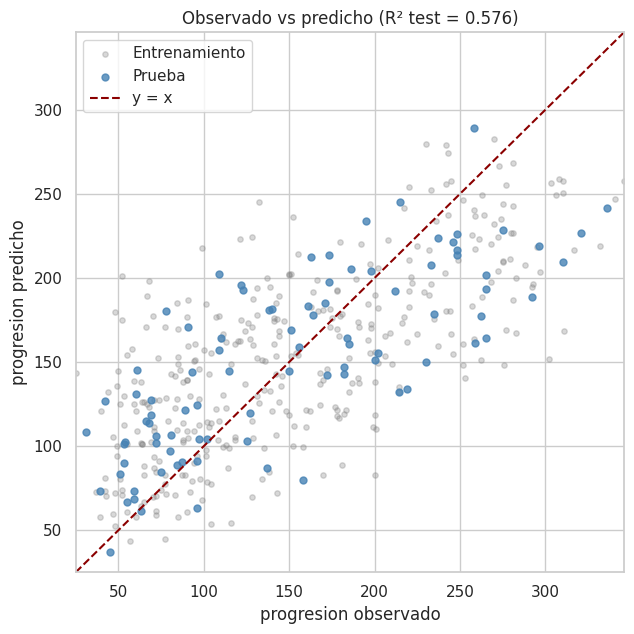

In [67]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(y_train, pred_train, alpha=0.3, s=15, color="grey", label="Entrenamiento")
ax.scatter(y_test, pred_test, alpha=0.8, s=25, color="steelblue", label="Prueba")
limites = [min(y.min(), pred_train.min(), pred_test.min()), max(y.max(), pred_train.max(), pred_test.max())]
ax.plot(limites, limites, color="darkred", ls="--", label="y = x")
ax.set_xlim(limites); ax.set_ylim(limites)
ax.set_xlabel(f"{variable_objetivo} observado"); ax.set_ylabel(f"{variable_objetivo} predicho")
ax.set_title(f"Observado vs predicho (R² test = {metricas_test['R2']:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

---
# PARTE 21. Predicciones

## 21.1 Predicciones sobre el conjunto de prueba

Se presenta, para cada observación de prueba, el valor real, el predicho, el residuo (real − predicho) y el error absoluto.

In [68]:
tabla_predicciones = pd.DataFrame({
    "Real": y_test, "Predicho": pred_test,
}, index=y_test.index)
tabla_predicciones["Residuo"] = tabla_predicciones["Real"] - tabla_predicciones["Predicho"]
tabla_predicciones["Error_absoluto"] = tabla_predicciones["Residuo"].abs()

display(Markdown("**Primeras 10 predicciones de prueba:**"))
display(tabla_predicciones.head(10))
display(Markdown("**Las 5 predicciones con mayor error absoluto:**"))
display(tabla_predicciones.sort_values("Error_absoluto", ascending=False).head(5))

**Primeras 10 predicciones de prueba:**

,Real,Predicho,Residuo,Error_absoluto
13,185.0000,160.8160,24.1840,24.1840
66,150.0000,144.8720,5.1280,5.1280
234,246.0000,221.5543,24.4457,24.4457
24,184.0000,164.0020,19.9980,19.9980
388,110.0000,164.3519,-54.3519,54.3519
72,202.0000,155.3567,46.6433,46.6433
138,336.0000,241.4332,94.5668,94.5668
384,69.0000,127.6032,-58.6032,58.6032
11,69.0000,118.6651,-49.6651,49.6651
33,87.0000,90.3637,-3.3637,3.3637


**Las 5 predicciones con mayor error absoluto:**

,Real,Predicho,Residuo,Error_absoluto
190,292.0000,188.7419,103.2581,103.2581
328,78.0000,180.4972,-102.4972,102.4972
9,310.0000,209.2347,100.7653,100.7653
280,265.0000,164.3203,100.6797,100.6797
232,259.0000,161.1209,97.8791,97.8791


## 21.2 Predicción para casos nuevos ✏️ EDITAR

**Intervalo de confianza vs intervalo de predicción:**

- **Intervalo de confianza (IC) de la media:** rango plausible para el **valor promedio** de $Y$ entre todos los individuos con esas características. Refleja sólo la incertidumbre en la estimación de los $\beta$.
- **Intervalo de predicción (IP):** rango plausible para el valor de $Y$ de **un individuo concreto** con esas características. Suma la incertidumbre de los $\beta$ y la variabilidad propia del error $\varepsilon$, por eso **siempre es más ancho**.

$$
\hat y_0 \pm t_{\alpha/2,\,n-p-1}\; \hat\sigma\sqrt{\mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0} \quad\text{(IC)}
\qquad\qquad
\hat y_0 \pm t_{\alpha/2,\,n-p-1}\; \hat\sigma\sqrt{1+\mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0} \quad\text{(IP)}
$$

Los casos nuevos se ingresan **en las variables originales** (antes de crear dummies); el cuadernillo aplica la misma codificación del entrenamiento. Por defecto, cada variable toma la mediana (numéricas) o la moda (categóricas) de la base, para que la celda sea ejecutable; **modifique los valores** según el escenario que quiera predecir.

In [69]:
# Valores por defecto: mediana (numéricas) o moda (categóricas) de los datos de modelamiento
valores_defecto = {c: datos_modelo[c].median() for c in pred_numericos}
valores_defecto.update({c: datos_modelo[c].mode().iloc[0] for c in pred_categoricos})

# ===============================================================
# ✏️ EDITAR: uno o varios casos nuevos (una fila por caso), en variables ORIGINALES
# ===============================================================
nuevo_caso = pd.DataFrame([
    valores_defecto,                                   # caso 1: "perfil típico"
    # {**valores_defecto, "imc": 32, "presion_arterial": 110},   # caso 2 (ejemplo editable)
])
display(Markdown("**Caso(s) nuevo(s) en variables originales:**"))
display(nuevo_caso)

# Misma codificación que en entrenamiento y sólo las columnas del modelo final
X_nuevo = codificar_predictores(nuevo_caso, pred_numericos, pred_categoricos, categorias)
X_nuevo = X_nuevo.reindex(columns=X.columns, fill_value=0.0)[predictores_finales]

# Advertencia de extrapolación: valores fuera del rango observado en entrenamiento
fuera = [(i, v, X_nuevo.loc[i, v]) for i in X_nuevo.index for v in predictores_finales
         if not (X_train[v].min() <= X_nuevo.loc[i, v] <= X_train[v].max())]
for i, v, val in fuera:
    print(f"⚠️ Caso {i}: {v} = {val} está fuera del rango de entrenamiento "
          f"[{X_train[v].min()}, {X_train[v].max()}] -> extrapolación.")

prediccion = modelo_final.get_prediction(con_constante(X_nuevo)).summary_frame(alpha=ALPHA)
nivel = int((1 - ALPHA) * 100)
prediccion = prediccion.rename(columns={
    "mean": "Prediccion_puntual", "mean_se": "Error_estandar_media",
    "mean_ci_lower": f"IC{nivel}_media_inf", "mean_ci_upper": f"IC{nivel}_media_sup",
    "obs_ci_lower": f"IP{nivel}_inf", "obs_ci_upper": f"IP{nivel}_sup",
})
display(Markdown("**Predicción, intervalo de confianza de la media e intervalo de predicción:**"))
display(prediccion)

**Caso(s) nuevo(s) en variables originales:**

,edad,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,sexo
0,50.0000,25.7000,93.0000,186.0000,113.0000,48.0000,4.0000,4.6200,91.0000,Grupo_1


**Predicción, intervalo de confianza de la media e intervalo de predicción:**

,Prediccion_puntual,Error_estandar_media,IC95_media_inf,IC95_media_sup,IP95_inf,IP95_sup
0,157.4445,4.4422,148.7074,166.1816,48.7487,266.1402


**Interpretación (plantilla):** *"Para un individuo con [características], el modelo estima un valor de $Y$ de [predicción puntual]. Con un 95% de confianza, el valor promedio de $Y$ para individuos con esas características está entre [IC inf] y [IC sup]; y el valor de un individuo particular se espera entre [IP inf] y [IP sup]."*

> Las predicciones sólo son válidas para la **población** representada por los datos y dentro del **rango de valores observados** de los predictores. Fuera de ese rango se extrapola y la linealidad puede no sostenerse.

## 📝 Para el informe: predicciones

Presente la tabla de predicciones de prueba (o un extracto), el gráfico observado vs predicho, y al menos un caso nuevo con su predicción puntual, IC e IP, explicando la diferencia entre ambos intervalos.

---
# PARTE 22. Conclusiones y recomendaciones

La celda siguiente reúne **automáticamente** los resultados clave como **insumo** para redactar las conclusiones. La conclusión debe escribirla usted.

In [70]:
sig = tabla_coef_final.drop("const")
sig = sig[sig["p_valor"] < ALPHA]

print("=== INSUMOS PARA LAS CONCLUSIONES ===\n")
print(f"Variable respuesta: {variable_objetivo} | n entrenamiento = {len(y_train)}, n prueba = {len(y_test)}")
print(f"Predictores del modelo final ({len(predictores_finales)}): {predictores_finales}\n")
print("Ecuación:", ec_final_texto, "\n")
print(f"Variables significativas al {int(ALPHA * 100)}%:")
for var, fila in sig.iterrows():
    print(f"  - {var}: coef = {fila['coeficiente']:.4f} ({'positiva' if fila['coeficiente'] > 0 else 'negativa'}), p = {fila['p_valor']:.4f}")
print(f"\nAjuste (train): R² = {metricas_train['R2']:.3f}, R² aj = {metricas_train['R2_ajustado']:.3f}, "
      f"RMSE = {metricas_train['RMSE']:.3f}, MAE = {metricas_train['MAE']:.3f}")
print(f"Predicción (test): R² = {metricas_test['R2']:.3f}, RMSE = {metricas_test['RMSE']:.3f}, MAE = {metricas_test['MAE']:.3f}")
print(f"Validación cruzada: RMSE = {rmse_folds.mean():.3f} ± {rmse_folds.std(ddof=1):.3f}")
print(f"VIF máximo del modelo final: {tabla_vif_final['VIF'].max():.2f}")
print(f"Lasso descartó: {descartadas_lasso if descartadas_lasso else 'ninguna variable'} (alpha = {lasso.alpha_:.4f})")
print(f"Ridge: alpha = {alpha_ridge:.4f}; RMSE test = {np.sqrt(mean_squared_error(y_test, pred_ridge_test)):.3f}")
print("\nDiagnóstico de supuestos:")
for fila in tabla_diag.itertuples():
    print(f"  - {fila.Diagnóstico}: {fila.Resultado} -> {fila.Interpretación}")

=== INSUMOS PARA LAS CONCLUSIONES ===

Variable respuesta: progresion | n entrenamiento = 353, n prueba = 89
Predictores del modelo final (5): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']

Ecuación: progresion_estimado = -212.721 + 5.574*imc + 39.892*log_trigliceridos + 1.047*presion_arterial - 1.140*hdl - 20.116*sexo_Grupo_2 

Variables significativas al 5%:
  - imc: coef = 5.5739 (positiva), p = 0.0000
  - log_trigliceridos: coef = 39.8917 (positiva), p = 0.0000
  - presion_arterial: coef = 1.0466 (positiva), p = 0.0000
  - hdl: coef = -1.1399 (negativa), p = 0.0000
  - sexo_Grupo_2: coef = -20.1158 (negativa), p = 0.0023

Ajuste (train): R² = 0.489, R² aj = 0.482, RMSE = 54.616, MAE = 44.233
Predicción (test): R² = 0.576, RMSE = 51.689, MAE = 42.836
Validación cruzada: RMSE = 55.342 ± 2.793
VIF máximo del modelo final: 1.50
Lasso descartó: ninguna variable (alpha = 0.0440)
Ridge: alpha = 0.0010; RMSE test = 52.194

Diagnóstico de supuestos:
  - Linealidad:

## Guía de preguntas para redactar las conclusiones

1. ¿Qué variables resultaron relevantes?
2. ¿Cuál fue su relación con $Y$ (signo y magnitud, en unidades reales)?
3. ¿Qué tan bien se ajusta el modelo ($R^2$, $R^2$ ajustado)?
4. ¿Qué tan bien predice (RMSE/MAE en prueba y en validación cruzada)? ¿Es ese error aceptable para el uso previsto?
5. ¿Se cumplen razonablemente los supuestos? ¿Qué implicaciones tienen las violaciones encontradas?
6. ¿Existen problemas de multicolinealidad?
7. ¿Qué mostró Lasso? ¿Coincide con la selección por p-valores?
8. ¿Qué mostró Ridge? ¿Mejora la predicción frente a OLS?
9. ¿El modelo es interpretable para el público objetivo?
10. ¿Cuáles son sus limitaciones (diseño observacional, variables omitidas, tamaño de muestra, calidad de medición)?
11. ¿En qué población y rango de valores deberían utilizarse las predicciones?
12. ¿Qué podría mejorarse (más datos, nuevas variables, transformaciones, interacciones, otros enfoques)?

*Conclusiones del estudiante:*

- ...

*Recomendaciones:*

- ...

---
# PARTE 23. Guía para elaborar el informe

Use esta plantilla. Entre corchetes se indica qué resultado del cuadernillo alimenta cada sección.

## 1. Descripción del problema y contexto
Contexto, relevancia, fuente de datos, unidad de análisis, variable respuesta (definición y unidades), predictores y objetivo. *[Parte 1, 3]*

## 2. Análisis exploratorio
Descriptivos, calidad de datos, distribución de $Y$, relaciones bivariadas, matriz de correlación y síntesis. *[Parte 4]*

## 3. Preparación de los datos
Predictores incluidos y excluidos (con razones), codificación dummy y categorías de referencia, tratamiento de faltantes y atípicos, partición entrenamiento/prueba. *[Partes 5, 6]*

## 4. Selección de variables
Criterios conceptuales, resultados de Backward, Forward, Stepwise, AIC/BIC, Lasso y Ridge; tabla comparativa. *[Partes 10–13]*

## 5. Modelo construido
Modelo final elegido y justificación con varios criterios; salida de coeficientes. *[Parte 14]*

## 6. Ecuación e interpretación
Ecuación estimada e interpretación de cada coeficiente relevante, sin lenguaje causal. *[Partes 8, 9, 14]*

## 7. Validación del modelo
Tabla resumen de diagnóstico, gráficos de residuos, Q-Q, Cook; discusión de cada supuesto. *[Partes 15, 16]*

## 8. Evaluación del ajuste
$R^2$, $R^2$ ajustado, MAE, RMSE en entrenamiento. *[Parte 17]*

## 9. Evaluación predictiva
Tabla train vs test, validación cruzada, gráfico observado vs predicho. *[Partes 18–20]*

## 10. Predicciones
Tabla de predicciones y caso(s) nuevo(s) con IC e IP. *[Parte 21]*

## 11. Conclusiones y recomendaciones
Respuestas a las preguntas de la Parte 22. *[Parte 22]*

## 12. Anexo: uso de Inteligencia Artificial
Según la Parte 24.

### Exportación opcional de tablas para el informe

Si `EXPORTAR_RESULTADOS = True`, se guarda un archivo Excel con las principales tablas (requiere `openpyxl`).

In [71]:
EXPORTAR_RESULTADOS = False   # ✏️ EDITAR: True para generar el archivo
ARCHIVO_RESULTADOS = "resultados_regresion_lineal_multiple.xlsx"

if EXPORTAR_RESULTADOS:
    with pd.ExcelWriter(ARCHIVO_RESULTADOS) as escritor:
        tabla_descriptivos.to_excel(escritor, sheet_name="descriptivos")
        matriz_corr.to_excel(escritor, sheet_name="correlaciones")
        tabla_coeficientes(modelo_completo).to_excel(escritor, sheet_name="coef_modelo_completo")
        tabla_vif_completo.to_excel(escritor, sheet_name="vif_completo", index=False)
        tabla_comparacion.to_excel(escritor, sheet_name="comparacion_modelos")
        tabla_coef_final.to_excel(escritor, sheet_name="coef_modelo_final")
        tabla_diag.to_excel(escritor, sheet_name="diagnostico", index=False)
        tabla_train_test.to_excel(escritor, sheet_name="metricas_train_test")
        tabla_cv.to_excel(escritor, sheet_name="validacion_cruzada")
        tabla_predicciones.to_excel(escritor, sheet_name="predicciones_test")
        prediccion.to_excel(escritor, sheet_name="casos_nuevos")
    print(f"Tablas exportadas a: {ARCHIVO_RESULTADOS}")
else:
    print("Exportación desactivada (EXPORTAR_RESULTADOS = False).")

Exportación desactivada (EXPORTAR_RESULTADOS = False).


---
# Anexo. Uso de Inteligencia Artificial

> Complete esta sección en su informe. Sea específico y honesto: el uso responsable y documentado de IA está permitido; el uso no declarado no.

### Herramienta utilizada

Indique la herramienta y, si la conoce, la versión o el modelo (por ejemplo: ChatGPT, Claude, Gemini, Copilot, etc.).

- ...

### Actividad realizada con IA

Marque y describa brevemente para qué la utilizó:

- [ ] comprender conceptos;
- [ ] generar código;
- [ ] corregir errores;
- [ ] interpretar resultados;
- [ ] revisar redacción;
- [ ] generar gráficos;
- [ ] plantear alternativas de análisis.

Descripción: ...

### Prompt empleado

Copie **literalmente** el o los prompts utilizados (puede usar un bloque de código para conservar el formato):

```text
[Pegue aquí el prompt exacto]
```

### Validación realizada

Explique cómo verificó:

- que el código funcionara (lo ejecutó completo, sin errores);
- que los cálculos fueran correctos (comparó con salidas de `statsmodels`/`sklearn`, recalculó alguna métrica a mano, etc.);
- que las interpretaciones coincidieran con los resultados obtenidos;
- que no se inventaran resultados (todas las cifras del informe provienen de la ejecución del cuadernillo);
- que la decisión final (variables, modelo, conclusiones) fue tomada por usted.

Descripción: ...

> **La IA puede apoyar el análisis, pero no sustituye la interpretación estadística ni la responsabilidad del estudiante sobre los resultados presentados.**

---
# PARTE 25. Lista de verificación final

- [ ] Definí el problema.
- [ ] Identifiqué la variable respuesta.
- [ ] Identifiqué los predictores.
- [ ] Revisé calidad de datos.
- [ ] Realicé análisis exploratorio.
- [ ] Separé entrenamiento y prueba.
- [ ] Construí el modelo completo.
- [ ] Analicé correlaciones.
- [ ] Evalué VIF.
- [ ] Probé selección Forward.
- [ ] Probé Backward.
- [ ] Probé Stepwise.
- [ ] Probé Lasso.
- [ ] Probé Ridge.
- [ ] Comparé alternativas.
- [ ] Seleccioné y justifiqué el modelo final.
- [ ] Escribí la ecuación.
- [ ] Interpreté coeficientes.
- [ ] Analicé residuos.
- [ ] Evalué normalidad.
- [ ] Evalué homocedasticidad.
- [ ] Evalué observaciones influyentes.
- [ ] Calculé R² y R² ajustado.
- [ ] Calculé MAE y RMSE.
- [ ] Evalué desempeño en test.
- [ ] Realicé validación cruzada.
- [ ] Realicé predicciones.
- [ ] Elaboré conclusiones.
- [ ] Documenté el uso de IA.